# Исследование транспортно-логистической сети на основе OpenStreetMap

**Учебный проект «Сервис по анализу региональной транспортно-логистической системы»**  
**Направление работы:** исследование данных и прототипирование модели графа (Data Science)  
**Формат:** воспроизводимые эксперименты в Python / Jupyter Notebook

## Цель исследования

Определить, насколько данные **OpenStreetMap (OSM)** и инструменты **OSMnx, GeoPandas и NetworkX** подходят для выделения логистических объектов и построения графа их потенциальной транспортной доступности. Отдельно проверить представление нескольких способов сообщения между объектами в одном мультиграфе.

**Порядок работы:**

1. Изучить структуру дорожного графа OSMnx.
2. Найти склады и потенциальные логистические комплексы, оценить качество OSM-разметки.
3. Исследовать железнодорожную и морскую инфраструктуру.
4. Создать единый реестр объектов с геометрией и исходными OSM ID.
5. Проверить маршрутизацию между объектами и построить демонстрационный `MultiGraph`.
6. Отобразить логический граф и реальные маршруты на карте.

> **Границы результатов.** Это исследовательский прототип, а не готовый сервис. Взаимодействие между регионами предусмотрено в модели, но ещё не проверено маршрутами. Полученные связи показывают **потенциальную достижимость по данным OSM**, а не фактические грузопотоки или гарантированный доступ грузового транспорта. Графовые метрики будут исследованы отдельно.

Далее представлены исходный код и **сохранённые результаты выполнения** ноутбука. Числа относятся к выбранным тестовым областям Санкт-Петербурга и могут измениться при обновлении OpenStreetMap.

## 1. Подготовка окружения и изучение OSMnx

Устанавливаем необходимые библиотеки. `OSMnx` отвечает за получение географических данных и дорожных графов из OSM; `NetworkX` — за работу с графами и маршрутизацию; `GeoPandas` и `Folium` — за пространственный анализ и визуализацию.

In [1]:
pip install osmnx networkx matplotlib jupyterlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 69.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.5/947.5 kB 47.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 94.5 MB/s eta 0:00:00


### 1.1. Загрузка дорожного графа

Для первой проверки используем ограниченную территорию в районе **Шушар**. Параметр `network_type="drive"` выбирает автомобильную сеть, а `retain_all=True` сохраняет в том числе несвязанные компоненты. Вершины такого графа соответствуют точкам дорожной сети, а **не складам или терминалам**.

Тип графа: <class 'networkx.classes.multidigraph.MultiDiGraph'>
Количество вершин: 179
Количество рёбер: 318
CRS: epsg:4326


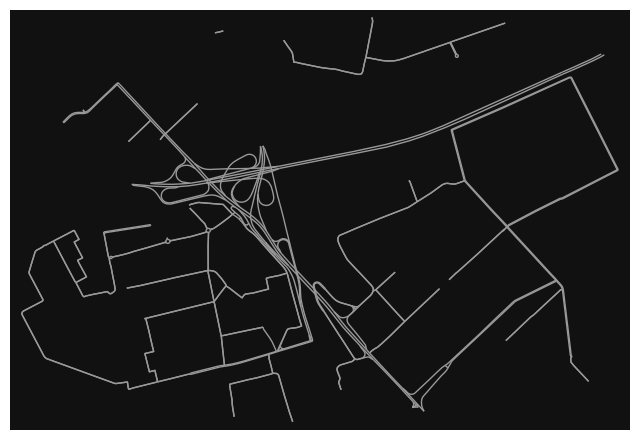

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [3]:

import osmnx as ox
import networkx as nx

ox.settings.use_cache = True
ox.settings.log_console = True

# Границы исследуемой территории:
# (запад, юг, восток, север)
bbox = (30.347782, 59.796599, 30.435798, 59.828174)

G = ox.graph.graph_from_bbox(
    bbox=bbox,
    network_type="drive",
    retain_all=True
)

print("Тип графа:", type(G))
print("Количество вершин:", G.number_of_nodes())
print("Количество рёбер:", G.number_of_edges())
print("CRS:", G.graph["crs"])

ox.plot.plot_graph(G, node_size=0)


**Наблюдение.** Получен направленный мультиграф `MultiDiGraph`: **179 вершин и 318 рёбер**. Это подтверждает, что OSMnx может подготовить инфраструктурный граф, который позднее будет использоваться как основа для поиска маршрутов между логистическими объектами.

### 1.2. Структура вершин и рёбер

Проверяем наличие координат (`x`, `y`) у вершин и атрибутов дороги (`length`, `highway`, `oneway`, геометрия и др.) у рёбер. Дополнительно оцениваем связность сети: в небольшой области дороги могут образовывать несколько независимых частей.

In [4]:
# Посмотрим на одну вершину
node_id = next(iter(G.nodes))
print("Вершина:", node_id)
print(G.nodes[node_id])

# Посмотрим на одно ребро
u, v, key, data = next(iter(G.edges(keys=True, data=True)))

print("\nРебро:", u, v, key)
print(data)

# Проверим связность графа
components = list(nx.weakly_connected_components(G))

print("\nКомпонент слабой связности:", len(components))
print("Размер крупнейшей:", max(map(len, components)))


Вершина: 699886
{'y': 59.8089631, 'x': 30.385136, 'street_count': 3}

Ребро: 699886 1382120532 0
{'osmid': [216912769, 332248840, 332248842, 23972816, 332248829, 31402815], 'highway': 'trunk', 'lanes': ['4', '3'], 'maxspeed': 'RU:urban', 'name': ['Витебский путепровод', 'Московское шоссе'], 'oneway': True, 'reversed': False, 'length': np.float64(910.1028180514659), 'bridge': 'yes', 'geometry': <LINESTRING (30.385 59.809, 30.386 59.809, 30.386 59.808, 30.387 59.808, 30....>}

Компонент слабой связности: 4
Размер крупнейшей: 168


**Наблюдение.** Для первоначального дорожного графа найдено **4 компоненты слабой связности**, из которых крупнейшая содержит **168 вершин**. Следовательно, даже в небольшой области нельзя предполагать, что все найденные дороги связаны между собой.

### 1.3. Проверка алгоритма кратчайшего пути

На крупнейшей сильно связной компоненте рассчитываем пример маршрута по атрибуту `length`. Начальная и конечная дорожные вершины выбраны условно — только для знакомства с API. Это **не маршрут между логистическими объектами**.

Длина маршрута: 8.97 км


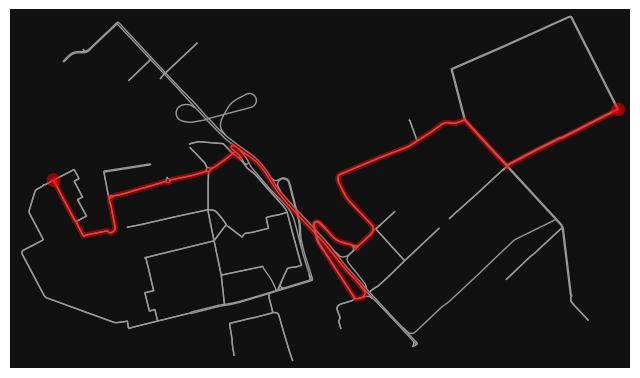

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [5]:

# Выбираем крупнейшую сильно связную компоненту,
# чтобы маршрут гарантированно существовал в обе стороны.
largest_scc = max(
    nx.strongly_connected_components(G),
    key=len
)

H = G.subgraph(largest_scc).copy()

# Берём самую западную и самую восточную вершины
source = min(H.nodes, key=lambda n: H.nodes[n]["x"])
target = max(H.nodes, key=lambda n: H.nodes[n]["x"])

# Кратчайший маршрут по длине
route = nx.shortest_path(
    H,
    source=source,
    target=target,
    weight="length"
)

# Получаем рёбра маршрута и суммируем их длину
route_edges = ox.routing.route_to_gdf(H, route)

distance_km = route_edges["length"].sum() / 1000

print(f"Длина маршрута: {distance_km:.2f} км")

ox.plot.plot_graph_route(H, route, node_size=0)


**Результат.** На выбранном примере длина маршрута составила **8,97 км**. Алгоритмы NetworkX позволяют рассчитывать путь по дорожному графу, однако для логистической модели сначала необходимо обнаружить сами объекты и определить способ их подключения к инфраструктуре.

## 2. Обнаружение складской инфраструктуры

### 2.1. Поиск объектов по OSM-тегам

В той же тестовой области ищем складские здания, складские территории и другие потенциально релевантные объекты. `features_from_bbox()` объединяет совпадения по перечисленным тегам; присутствие одного подходящего тега **не доказывает**, что объект является самостоятельным логистическим центром.

In [6]:
import osmnx as ox
import geopandas as gpd
import pandas as pd
import folium

ox.settings.use_cache = True

# Границы нашей тестовой области
bbox = (30.347782, 59.796599, 30.435798, 59.828174)

tags = {
    "building": "warehouse",
    "building:use": "warehouse",
    "industrial": ["warehouse", "logistics"],
    "amenity": "post_depot",
}

objects = ox.features.features_from_bbox(
    bbox=bbox,
    tags=tags
)

print("Найдено объектов:", len(objects))

display(objects.head())

Найдено объектов: 24


geometry  \
element id                                                               
node    10844030702                           POINT (30.39773 59.8031)   
way     78401306     POLYGON ((30.39518 59.81718, 30.39554 59.81707...   
        78401309     POLYGON ((30.40051 59.80774, 30.40076 59.80786...   
        78401313     POLYGON ((30.39829 59.8055, 30.39968 59.80615,...   
        78401324     POLYGON ((30.40093 59.80795, 30.40119 59.80806...   

                      building               contact:email   contact:phone  \
element id                                                                   
node    10844030702  warehouse  marketing.maslov@yandex.ru  +7 812 7704300   
way     78401306     warehouse                         NaN             NaN   
        78401309     warehouse                         NaN             NaN   
        78401313     warehouse                         NaN             NaN   
        78401324     warehouse                         NaN             NaN   

                          contact:website          name opening_hours  \
element id                                                              
node    10844030702  https://hranilkin.ru  Хранилкин.рф          24/7   
way     78401306                      NaN           NaN           NaN   
        78401309                      NaN           NaN           NaN   
        78401313                      NaN           NaN           NaN   
        78401324                      NaN           NaN           NaN   

                    addr:housenumber            addr:street  \
element id                                                    
node    10844030702              NaN                    NaN   
way     78401306                 NaN                    NaN   
        78401309                  9В  1-й Бадаевский проезд   
        78401313                  5А                    NaN   
        78401324                  9Б  1-й Бадаевский проезд   

                               addr:place            operator  \
element id                                                      
node    10844030702                   NaN                 NaN   
way     78401306                      NaN                 NaN   
        78401309                      NaN                 NaN   
        78401313     Бадаевское отделение  ООО "ТД Интерторг"   
        78401324                      NaN                 NaN   

                    source:addr:place addr:city building:levels height  
element id                                                              
node    10844030702               NaN       NaN             NaN    NaN  
way     78401306                  NaN       NaN             NaN    NaN  
        78401309                  NaN       NaN             NaN    NaN  
        78401313                 rgis       NaN             NaN    NaN  
        78401324                  NaN       NaN             NaN    NaN

### 2.2. Первичная классификация

Разделяем найденные объекты на категории в зависимости от тегов. Эта классификация является **эвристической**, поскольку OSM фиксирует тип здания и назначение территории не всегда одинаково подробно.

In [7]:
objects = objects.copy()

def classify_object(row):
    if row.get("industrial") == "logistics":
        return "Логистический комплекс"

    if row.get("industrial") == "warehouse":
        return "Складская территория"

    if row.get("amenity") == "post_depot":
        return "Распределительный центр"

    if row.get("building:use") == "warehouse":
        return "Здание, используемое как склад"

    if row.get("building") == "warehouse":
        return "Складское здание"

    return "Неопределённый объект"


objects["object_type"] = objects.apply(
    classify_object,
    axis=1
)

print(objects["object_type"].value_counts())

object_type
Складское здание    24
Name: count, dtype: int64


**Результат.** Найдено **24 объекта**, и все они получили категорию «Складское здание». Следовательно, из выбранного набора OSM-тегов в тестовой области сработал прежде всего `building=warehouse`. Отсутствие специализированных объектов в выдаче не означает их физического отсутствия.

### 2.3. Получение координат

Объекты OSM могут быть точками или полигонами. Для унифицированного отображения вычисляем `representative_point()` — точку внутри геометрии объекта. При этом исходная геометрия сохраняется и будет использоваться для дальнейших пространственных операций.

> Репрезентативная точка не равнозначна въезду грузовика, месту погрузки или точке соединения с дорогой.

In [8]:
# Переходим в метрическую систему координат
projected = objects.to_crs(objects.estimate_utm_crs())

# Находим внутреннюю точку каждого объекта
points_projected = projected.geometry.representative_point()

# Создаём GeoDataFrame с точками
points = gpd.GeoDataFrame(
    objects.drop(columns="geometry"),
    geometry=points_projected,
    crs=projected.crs
).to_crs(epsg=4326)

points["latitude"] = points.geometry.y
points["longitude"] = points.geometry.x

points["osm_type"] = points.index.get_level_values(0)
points["osm_id"] = points.index.get_level_values(1)

display(
    points[
        ["osm_type", "osm_id", "object_type",
         "latitude", "longitude"]
    ].head(15)
)

osm_type       osm_id       object_type   latitude  \
element id                                                               
node    10844030702     node  10844030702  Складское здание  59.803101   
way     78401306         way     78401306  Складское здание  59.815828   
        78401309         way     78401309  Складское здание  59.807595   
        78401313         way     78401313  Складское здание  59.805420   
        78401324         way     78401324  Складское здание  59.807841   
        78697309         way     78697309  Складское здание  59.803301   
        78697315         way     78697315  Складское здание  59.801989   
        78697316         way     78697316  Складское здание  59.803402   
        155640971        way    155640971  Складское здание  59.800401   
        423843614        way    423843614  Складское здание  59.796424   
        497854926        way    497854926  Складское здание  59.797668   
        497854939        way    497854939  Складское здание  59.799815   
        497854942        way    497854942  Складское здание  59.799794   
        612740973        way    612740973  Складское здание  59.798374   
        813195812        way    813195812  Складское здание  59.807849   

                     longitude  
element id                      
node    10844030702  30.397727  
way     78401306     30.395268  
        78401309     30.401005  
        78401313     30.399755  
        78401324     30.401549  
        78697309     30.403285  
        78697315     30.405729  
        78697316     30.410524  
        155640971    30.373924  
        423843614    30.403829  
        497854926    30.375913  
        497854939    30.381177  
        497854942    30.378516  
        612740973    30.379086  
        813195812    30.407293

### 2.4. Первичная визуализация складов

Показываем найденные объекты на интерактивной карте. В качестве подложки используется **OpenTopoMap**, поскольку при проведении экспериментов исходный сервер тайлов OSM и альтернативная подложка были недоступны.

In [14]:
import folium

west, south, east, north = bbox

m = folium.Map(
    location=[(south + north) / 2, (west + east) / 2],
    zoom_start=13,
    tiles="OpenTopoMap"
)

colors = {
    "Логистический комплекс": "red",
    "Складская территория": "orange",
    "Распределительный центр": "purple",
    "Складское здание": "blue",
    "Здание, используемое как склад": "green"
}

for _, row in points.iterrows():
    obj_type = row["object_type"]
    color = colors.get(obj_type, "gray")

    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=6,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.8,
        tooltip=f"{obj_type} (OSM ID: {row['osm_id']})"
    ).add_to(m)

# Показываем всю исследуемую область
m.fit_bounds([
    [south, west],
    [north, east]
])

m

### 2.5. Проверка атрибутов и полноты описания

Выводим названия, OSM ID, типы зданий и операторов. Нас интересует, какие данные действительно доступны для автоматического выделения логистических вершин.

In [15]:
# Количество объектов каждого типа
display(
    points["object_type"]
    .value_counts()
    .rename_axis("Тип объекта")
    .reset_index(name="Количество")
)

# Посмотрим на доступные характеристики
columns = [
    "osm_type",
    "osm_id",
    "name",
    "object_type",
    "building",
    "building:use",
    "industrial",
    "amenity",
    "operator"
]

columns = [col for col in columns if col in points.columns]

display(points[columns].head(30))

,Тип объекта,Количество
0,Складское здание,24


osm_type       osm_id                          name  \
element id                                                                
node    10844030702     node  10844030702                  Хранилкин.рф   
way     78401306         way     78401306                           NaN   
        78401309         way     78401309                           NaN   
        78401313         way     78401313                           NaN   
        78401324         way     78401324                           NaN   
        78697309         way     78697309                           NaN   
        78697315         way     78697315  Логистический терминал "PNK"   
        78697316         way     78697316                           NaN   
        155640971        way    155640971                           NaN   
        423843614        way    423843614                           NaN   
        497854926        way    497854926                           NaN   
        497854939        way    497854939                           NaN   
        497854942        way    497854942                           NaN   
        612740973        way    612740973                           NaN   
        813195812        way    813195812                           NaN   
        872280696        way    872280696                           NaN   
        1267681500       way   1267681500                           NaN   
        1267681501       way   1267681501                           NaN   
        1267681502       way   1267681502                           NaN   
        1306655137       way   1306655137                           NaN   
        1368691811       way   1368691811                           NaN   
        1368691812       way   1368691812                           NaN   
        1368691813       way   1368691813                           NaN   
        1441908752       way   1441908752                           NaN   

                          object_type   building            operator  
element id                                                            
node    10844030702  Складское здание  warehouse                 NaN  
way     78401306     Складское здание  warehouse                 NaN  
        78401309     Складское здание  warehouse                 NaN  
        78401313     Складское здание  warehouse  ООО "ТД Интерторг"  
        78401324     Складское здание  warehouse                 NaN  
        78697309     Складское здание  warehouse                 NaN  
        78697315     Складское здание  warehouse                 NaN  
        78697316     Складское здание  warehouse                 NaN  
        155640971    Складское здание  warehouse                 NaN  
        423843614    Складское здание  warehouse                 NaN  
        497854926    Складское здание  warehouse                 NaN  
        497854939    Складское здание  warehouse                 NaN  
        497854942    Складское здание  warehouse                 NaN  
        612740973    Складское здание  warehouse                 NaN  
        813195812    Складское здание  warehouse                 NaN  
        872280696    Складское здание  warehouse                 NaN  
        1267681500   Складское здание  warehouse                 NaN  
        1267681501   Складское здание  warehouse                 NaN  
        1267681502   Складское здание  warehouse                 NaN  
        1306655137   Складское здание  warehouse                 NaN  
        1368691811   Складское здание  warehouse                 NaN  
        1368691812   Складское здание  warehouse                 NaN  
        1368691813   Складское здание  warehouse                 NaN  
        1441908752   Складское здание  warehouse                 NaN

### 2.6. Визуализация геометрий

Вместо одного маркера на объект отображаем контур полигона, если он имеется в OSM. Это важно для исследования групп складских зданий и их потенциальной принадлежности комплексам.

In [16]:
import folium
import pandas as pd
from html import escape

west, south, east, north = bbox

m = folium.Map(
    location=[(south + north) / 2, (west + east) / 2],
    zoom_start=13,
    tiles="OpenTopoMap"
)

for (osm_type, osm_id), row in objects.iterrows():
    geom = row.geometry

    name = row.get("name")
    name = str(name) if pd.notna(name) else "Без названия"

    popup = (
        f"<b>{escape(name)}</b><br>"
        f"Тип: {escape(str(row['object_type']))}<br>"
        f"OSM ID: {osm_id}"
    )

    if geom.geom_type in ["Polygon", "MultiPolygon"]:
        folium.GeoJson(
            data={
                "type": "Feature",
                "geometry": geom.__geo_interface__,
                "properties": {}
            },
            style_function=lambda feature: {
                "color": "red",
                "weight": 2,
                "fillColor": "orange",
                "fillOpacity": 0.35
            },
            tooltip=name,
            popup=folium.Popup(popup, max_width=300)
        ).add_to(m)

    elif geom.geom_type == "Point":
        folium.CircleMarker(
            location=[geom.y, geom.x],
            radius=6,
            color="blue",
            fill=True,
            tooltip=name,
            popup=folium.Popup(popup, max_width=300)
        ).add_to(m)

m.fit_bounds([[south, west], [north, east]])
m


### 2.7. Пример неполной классификации: терминал PNK

Проверяем все заполненные атрибуты здания с названием «Логистический терминал PNK», чтобы сопоставить текстовое название и формальный тип OSM.

In [17]:
pnk = objects.loc[("way", 78697315)]

display(
    pnk.dropna().drop(labels=["geometry"], errors="ignore")
)

,way
,78697315
building,warehouse
name,"Логистический терминал ""PNK"""
addr:housenumber,19 к2
addr:street,Московское шоссе
addr:city,Шушары
object_type,Складское здание


**Вывод по складским объектам.** Среди 24 объектов **23 представлены контурами зданий (`way`) и один — точкой (`node`)**. У большинства нет названия или оператора. Терминал **PNK** размечен как `building=warehouse` и имеет адрес, но не содержит отдельного признака принадлежности логистическому комплексу. Следовательно, **нельзя создавать вершины графа, ориентируясь только на тег здания**; потребуется проверка названий и пространственных отношений.

## 3. Промышленные территории и выделение комплексов

### 3.1. Поиск территорий

Ищем полигоны `landuse=industrial` и территории с явными складскими или логистическими тегами. **Промышленная зона — это географический контекст, а не автоматически логистическая вершина**.

In [18]:
area_tags = {
    "landuse": "industrial",
    "industrial": ["warehouse", "logistics"]
}

areas_raw = ox.features_from_bbox(
    bbox=bbox,
    tags=area_tags
)

# Оставляем только территории с геометрией полигона
areas = areas_raw[
    areas_raw.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

if "industrial" not in areas.columns:
    areas["industrial"] = None

site_types = {
    "warehouse": "Складская территория",
    "logistics": "Логистический комплекс"
}

areas["site_type"] = (
    areas["industrial"]
    .map(site_types)
    .fillna("Промышленная территория")
)

print("Всего территорий:", len(areas))
print(areas["site_type"].value_counts())

Всего территорий: 106
site_type
Промышленная территория    106
Name: count, dtype: int64


**Результат.** Найдено **106 промышленных территорий**. Ни одна не была отнесена нашим правилом к отдельной категории «складская территория» или «логистический комплекс». Проверим исходные теги, чтобы понять причину.

### 3.2. Сопоставление территорий со складскими зданиями на карте

Отображаем два независимых слоя: границы территорий и контуры складов. Пространственная близость или попадание в один полигон само по себе **не подтверждает**, что несколько зданий принадлежат одному оператору.

In [19]:
m = folium.Map(
    location=[(south + north) / 2, (west + east) / 2],
    zoom_start=13,
    tiles="OpenTopoMap"
)

area_colors = {
    "Промышленная территория": "gray",
    "Складская территория": "orange",
    "Логистический комплекс": "green"
}

# Слой территорий
area_layer = folium.FeatureGroup(
    name="Промышленные и складские территории"
)

for _, row in areas.iterrows():
    color = area_colors[row["site_type"]]

    folium.GeoJson(
        row.geometry.__geo_interface__,
        style_function=lambda feature, c=color: {
            "color": c,
            "weight": 2,
            "fillColor": c,
            "fillOpacity": 0.12
        },
        tooltip=row["site_type"]
    ).add_to(area_layer)

area_layer.add_to(m)

# Слой складских зданий
warehouse_layer = folium.FeatureGroup(
    name="Складские здания"
)

for _, row in objects.iterrows():
    geom = row.geometry

    if geom.geom_type in ["Polygon", "MultiPolygon"]:
        folium.GeoJson(
            geom.__geo_interface__,
            style_function=lambda feature: {
                "color": "red",
                "weight": 2,
                "fillColor": "red",
                "fillOpacity": 0.45
            }
        ).add_to(warehouse_layer)

    elif geom.geom_type == "Point":
        folium.CircleMarker(
            [geom.y, geom.x],
            radius=6,
            color="blue",
            fill=True
        ).add_to(warehouse_layer)

warehouse_layer.add_to(m)

folium.LayerControl().add_to(m)

m.fit_bounds([[south, west], [north, east]])
m

### 3.3. Анализ исходных тегов территорий

Смотрим, насколько подробно описано назначение каждого промышленного участка.

In [20]:
for col in ["landuse", "industrial"]:
    if col in areas.columns:
        print(f"\n{col}:")
        print(areas[col].value_counts(dropna=False))


landuse:
landuse
industrial    106
Name: count, dtype: int64

industrial:
industrial
NaN        100
depot        4
factory      2
Name: count, dtype: int64


**Наблюдение.** У всех 106 территорий указан `landuse=industrial`, однако **100** не имеют дополнительного значения `industrial`, **4** размечены как `depot`, **2** — как `factory`. Явных `industrial=warehouse` и `industrial=logistics` не выявлено. Значит, специализированные признаки логистики следует искать не только в `industrial`, но и в названии, окружении и дополнительных тегах.

### 3.4. Пространственное сопоставление складов и территорий

При помощи `GeoPandas.sjoin()` выясняем, внутри каких промышленных полигонов расположены репрезентативные точки складов. Геометрии временно переводятся в метрическую систему координат.

In [21]:

import geopandas as gpd
import pandas as pd

# Работаем в метрической системе координат
metric_crs = objects.estimate_utm_crs()

# Подготавливаем складские объекты
warehouses = objects.reset_index().copy()

if "name" not in warehouses.columns:
    warehouses["name"] = pd.NA

warehouses = warehouses[
    ["element", "id", "name", "geometry"]
].rename(columns={
    "element": "warehouse_osm_type",
    "id": "warehouse_osm_id",
    "name": "warehouse_name"
}).to_crs(metric_crs)

# Получаем точки внутри складов
warehouse_points = warehouses.copy()
warehouse_points["geometry"] = (
    warehouses.geometry.representative_point()
)

# Подготавливаем промышленные территории
territories = areas.reset_index().copy()

if "name" not in territories.columns:
    territories["name"] = pd.NA

territories = territories[
    ["element", "id", "name", "site_type", "geometry"]
].rename(columns={
    "element": "territory_osm_type",
    "id": "territory_osm_id",
    "name": "territory_name"
}).to_crs(metric_crs)

territories["area_km2"] = (
    territories.geometry.area / 1_000_000
)

# Пространственное соединение
joined = gpd.sjoin(
    warehouse_points,
    territories,
    how="left",
    predicate="within"
)

# Считаем уникальные склады, попавшие в территории
matched = joined.loc[
    joined["territory_osm_id"].notna(),
    "warehouse_osm_id"
].nunique()

print(f"Всего складов: {len(warehouses)}")
print(f"Складов внутри территорий: {matched}")
print(f"Складов без найденной территории: {len(warehouses) - matched}")

display(
    joined[
        [
            "warehouse_osm_id",
            "warehouse_name",
            "territory_osm_id",
            "territory_name",
            "site_type"
        ]
    ].head(30)
)


Всего складов: 24
Складов внутри территорий: 21
Складов без найденной территории: 3


,warehouse_osm_id,warehouse_name,territory_osm_id,territory_name,site_type
0,10844030702,Хранилкин.рф,NaN,NaN,NaN
1,78401306,NaN,5831201.0,"Терминал ""Евросиб""",Промышленная территория
2,78401309,NaN,155262279.0,NaN,Промышленная территория
3,78401313,NaN,5817365.0,NaN,Промышленная территория
4,78401324,NaN,155262279.0,NaN,Промышленная территория
5,78697309,NaN,6950698.0,NaN,Промышленная территория
6,78697315,"Логистический терминал ""PNK""",6950698.0,NaN,Промышленная территория
7,78697316,NaN,149521870.0,NaN,Промышленная территория
8,155640971,NaN,175946498.0,NaN,Промышленная территория
9,423843614,NaN,6950685.0,Распределительный центр «Пятерочка»,Промышленная территория


**Результат.** **21 из 24** складских объектов попал в найденные промышленные территории, **3** остались вне них. Это проверка попадания **репрезентативной точки**, а не полного покрытия геометрии здания. Она выявляет кандидатов на группировку, но не подтверждает организационную принадлежность.

### 3.5. Количество складов на одну территорию

Подсчитываем уникальные здания в каждой территории, чтобы определить участки, заслуживающие дальнейшей проверки. Несколько складов в одном полигоне — это **признак для исследования**, а не готовый результат объединения.

In [22]:
candidates = (
    joined.dropna(subset=["territory_osm_id"])
    .groupby(["territory_osm_type", "territory_osm_id"])
    .agg(
        territory_name=("territory_name", "first"),
        site_type=("site_type", "first"),
        warehouse_count=("warehouse_osm_id", "nunique"),
        area_km2=("area_km2", "first")
    )
    .reset_index()
    .sort_values("warehouse_count", ascending=False)
)

display(candidates.head(20))

,territory_osm_type,territory_osm_id,territory_name,site_type,warehouse_count,area_km2
7,way,301434906.0,None,Промышленная территория,4,0.019968
8,way,506575025.0,None,Промышленная территория,3,0.100183
9,way,626719131.0,None,Промышленная территория,3,0.031969
5,way,155262279.0,None,Промышленная территория,2,0.041987
10,way,872280695.0,None,Промышленная территория,2,0.030212
3,relation,6950698.0,None,Промышленная территория,2,0.095932
0,relation,5817365.0,None,Промышленная территория,1,0.026986
2,relation,6950685.0,Распределительный центр «Пятерочка»,Промышленная территория,1,0.064345
1,relation,5831201.0,"Терминал ""Евросиб""",Промышленная территория,1,0.142097
6,way,175946498.0,None,Промышленная территория,1,0.025090


### 3.6. Формирование списка потенциальных логистических территорий

Объединяем три источника свидетельств: наличие складских зданий, специализированный тег и ключевые слова в названии (`логист`, `терминал`, `распределител`, `склад`, `груз` и др.). Для каждого кандидата фиксируем **причину включения**.

In [24]:
import pandas as pd

# Количество уникальных складов на каждой территории
counts = (
    joined.dropna(subset=["territory_osm_id"])
    .groupby(["territory_osm_type", "territory_osm_id"])
    ["warehouse_osm_id"]
    .nunique()
    .rename("warehouse_count")
    .reset_index()
)

# Информация о промышленных территориях
sites = (
    areas.reset_index()
    .rename(columns={
        "element": "territory_osm_type",
        "id": "territory_osm_id"
    })
    .merge(
        counts,
        on=["territory_osm_type", "territory_osm_id"],
        how="left"
    )
)

sites["warehouse_count"] = (
    sites["warehouse_count"]
    .fillna(0)
    .astype(int)
)

# Ищем названия, указывающие на логистическую деятельность
pattern = (
    r"логист|терминал|распределител|"
    r"склад|груз|транспорт"
)

sites["logistics_name"] = (
    sites["name"]
    .fillna("")
    .str.contains(pattern, case=False, regex=True)
)

# Проверяем специализированные OSM-теги
sites["explicit_logistics_tag"] = (
    sites["industrial"].isin(["warehouse", "logistics"])
)

# Объясняем причину включения территории в кандидаты
def candidate_reason(row):
    if row["explicit_logistics_tag"]:
        return "Специализированный OSM-тег"

    if row["logistics_name"]:
        return "Название указывает на логистику"

    if row["warehouse_count"] > 0:
        return "Есть складские здания, требуется проверка"

    return "Нет подтверждения"


sites["candidate_reason"] = sites.apply(
    candidate_reason,
    axis=1
)

# Оставляем только потенциальные логистические объекты
candidates = sites[
    sites["warehouse_count"].gt(0)
    | sites["logistics_name"]
    | sites["explicit_logistics_tag"]
].copy()

display(
    candidates[
        [
            "territory_osm_type",
            "territory_osm_id",
            "name",
            "industrial",
            "warehouse_count",
            "candidate_reason"
        ]
    ].sort_values("warehouse_count", ascending=False)
)

,territory_osm_type,territory_osm_id,name,industrial,warehouse_count,candidate_reason
61,way,301434906,NaN,NaN,4,"Есть складские здания, требуется проверка"
69,way,506575025,NaN,NaN,3,"Есть складские здания, требуется проверка"
76,way,626719131,NaN,NaN,3,"Есть складские здания, требуется проверка"
44,way,155262279,NaN,NaN,2,"Есть складские здания, требуется проверка"
12,relation,6950698,NaN,NaN,2,"Есть складские здания, требуется проверка"
78,way,872280695,NaN,NaN,2,"Есть складские здания, требуется проверка"
6,relation,5817365,NaN,NaN,1,"Есть складские здания, требуется проверка"
32,way,149521870,NaN,NaN,1,"Есть складские здания, требуется проверка"
8,relation,5831201,"Терминал ""Евросиб""",NaN,1,Название указывает на логистику
10,relation,6950685,Распределительный центр «Пятерочка»,NaN,1,Название указывает на логистику


**Результат.** Получено **14 территорий-кандидатов**: **11** содержат ранее обнаруженные складские здания, а **3** дополнительных объекта попали в выборку по названию. Среди именованных объектов — терминалы **«Евросиб»** и **«Руслан»**, распределительный центр **«Пятёрочка»**, склад **«Софийская»** и производственно-складской комплекс **Wurth**.

> `warehouse_count = 0` означает только, что внутри не нашлось объектов **из нашего первоначального набора** `building=warehouse`; это не доказательство отсутствия складов.

### 3.7. Исключение нерелевантных депо

Отдельно рассматриваем территории `industrial=depot`: термин «депо» может относиться к пассажирскому транспорту и не гарантирует связь с грузовой логистикой.

In [25]:
depots = sites[
    sites["industrial"] == "depot"
].copy()

columns = [
    "territory_osm_type",
    "territory_osm_id",
    "name",
    "industrial",
    "warehouse_count"
]

# Добавляем дополнительные атрибуты, если они присутствуют
for col in ["depot", "operator", "description"]:
    if col in depots.columns:
        columns.append(col)

display(depots[columns])

,territory_osm_type,territory_osm_id,name,industrial,warehouse_count,depot,operator,description
1,relation,1756027,Электродепо «Московское» (ТЧ-3),depot,0,subway,ГУП «Петербургский метрополитен»,NaN
17,relation,7159179,Электродепо «Южное» (ТЧ-7),depot,0,subway,ГУП «Петербургский метрополитен»,NaN
18,relation,7182555,Автостанция «‎Малая Балканская улица»,depot,0,bus,NaN,NaN
59,way,191205712,"Автостанция ""Московское шоссе, 33""",depot,0,bus,NaN,NaN


**Результат и решение.** Все **4** обнаруженных депо относятся к **метрополитену (2)** или **автобусному транспорту (2)**. Не включаем их в реестр грузовой логистики только на основании тега `industrial=depot`. Этот пример демонстрирует необходимость фильтрации по функциональному назначению.

## 4. Исследование железнодорожной инфраструктуры

### 4.1. Поиск железнодорожных объектов

Получаем станции, парки и погрузочные площадки на той же территории Шушар. Цель — оценить, можно ли автоматически отличить грузовую инфраструктуру от пассажирской.

In [26]:
rail_tags = {
    "railway": [
        "station",
        "yard",
        "loading_ramp"
    ]
}

rail_objects = ox.features_from_bbox(
    bbox=bbox,
    tags=rail_tags
)

print("Всего найдено:", len(rail_objects))

display(
    rail_objects["railway"]
    .value_counts()
    .rename_axis("Тип объекта")
    .reset_index(name="Количество")
)

Всего найдено: 6


,Тип объекта,Количество
0,station,6


### 4.2. Проверка типов найденных станций

Анализируем названия и дополнительные признаки (`station=subway`, `subway=yes`, оператор). **Любая железнодорожная станция не обязательно является грузовым терминалом**.

In [27]:
rail_df = rail_objects.reset_index()

columns = [
    "element",
    "id",
    "railway",
    "name",
    "station",
    "subway",
    "operator",
    "railway:yard:purpose",
    "railway:station_category"
]

columns = [
    col for col in columns
    if col in rail_df.columns
]

display(
    rail_df[columns]
    .sort_values("railway")
)

,element,id,railway,name,station,subway,operator
0,node,922690113,station,Юный,NaN,NaN,ОАО «РЖД»
1,node,1002512043,station,Купчинская,NaN,NaN,ОАО «РЖД»
2,node,1002512045,station,Среднерогатская,NaN,NaN,ОАО «РЖД»
3,node,1371730163,station,Молодёжная,NaN,NaN,ОАО «РЖД»
4,node,1377619868,station,Шушары,NaN,NaN,ОАО «РЖД»
5,node,4709806344,station,Шушары,subway,yes,ГУП «Петербургский метрополитен»


**Результат.** Найдено **6 станций** с `railway=station`: **5 объектов РЖД** и **1 станция метро «Шушары»**. Метро исключаем; грузовую функцию остальных пяти пока оставляем **неподтверждённой**. В текущем запросе не было найдено объектов `railway=yard` и `railway=loading_ramp`.

### 4.3. Загрузка железнодорожных линий

Отдельно ищем линейные объекты `railway=rail`. Одна железнодорожная ветка может состоять из множества объектов `way`, поэтому число найденных линий нельзя интерпретировать как число независимых маршрутов.

In [29]:
rail_lines = ox.features_from_bbox(
    bbox=bbox,
    tags={"railway": "rail"}
)

rail_lines = rail_lines[
    rail_lines.geometry.geom_type.isin(
        ["LineString", "MultiLineString"]
    )
].copy()

print("Найдено участков железнодорожных путей:", len(rail_lines))

Найдено участков железнодорожных путей: 103


### 4.4. Анализ атрибутов путей

Проверяем `usage`, `service`, колею и другие доступные признаки. Приоритет имеют `service=spur` (ответвления) и `service=siding` (боковые пути), которые могут быть связаны с обслуживанием грузовых объектов.

In [30]:
attributes = [
    "usage",
    "service",
    "railway:traffic_mode",
    "gauge",
    "access"
]

for attr in attributes:
    if attr in rail_lines.columns:
        print(f"\n{attr}:")
        print(rail_lines[attr].value_counts(dropna=False))
    else:
        print(f"\n{attr}: тег отсутствует")


usage:
usage
NaN     80
main    23
Name: count, dtype: int64

service:
service
siding       41
NaN          30
spur         27
crossover     5
Name: count, dtype: int64

railway:traffic_mode: тег отсутствует

gauge:
gauge
1520    64
NaN     39
Name: count, dtype: int64

access: тег отсутствует


### 4.5. Предварительный отбор путей, потенциально связанных с грузовой деятельностью

Это **эвристический отбор**, а не классификация путей как действующих грузовых: значение `siding` встречается и у инфраструктуры иного назначения.

In [31]:
def get_column(gdf, name):
    if name in gdf.columns:
        return gdf[name].fillna("").astype(str)
    return pd.Series("", index=gdf.index)

usage = get_column(rail_lines, "usage")
service = get_column(rail_lines, "service")
traffic_mode = get_column(
    rail_lines, "railway:traffic_mode"
)

freight_related = rail_lines[
    usage.eq("industrial")
    | service.isin(["spur", "siding", "yard"])
    | traffic_mode.eq("freight")
].copy()

print(
    "Участков с признаками возможной грузовой инфраструктуры:",
    len(freight_related)
)

columns = [
    "name",
    "usage",
    "service",
    "railway:traffic_mode",
    "operator"
]

columns = [
    col for col in columns
    if col in freight_related.columns
]

display(freight_related[columns].head(30))

Участков с признаками возможной грузовой инфраструктуры: 68


usage service                          operator
element id                                                       
way     32874055    NaN    spur                               NaN
        32874056    NaN    spur                               NaN
        32874058    NaN    spur  ОАО «Российские железные дороги»
        48772404    NaN    spur                               NaN
        51245014    NaN    spur                               NaN
        54533059    NaN    spur                               NaN
        78626931    NaN    spur                               NaN
        78626942    NaN    spur                               NaN
        78629597    NaN  siding                               NaN
        78629602    NaN  siding                               NaN
        78629629    NaN  siding                               NaN
        78629632    NaN  siding                               NaN
        78629648    NaN  siding                               NaN
        78629652    NaN  siding                               NaN
        78691558    NaN  siding                               NaN
        78691637    NaN  siding                               NaN
        120608623   NaN    spur                               NaN
        124100872   NaN  siding                               NaN
        124186590   NaN  siding                               NaN
        124186602   NaN  siding                               NaN
        124186603   NaN  siding                               NaN
        124186606   NaN  siding                               NaN
        124186610   NaN  siding                               NaN
        124186612   NaN  siding                               NaN
        155266847   NaN  siding                               NaN
        165915135   NaN  siding  ОАО «Российские железные дороги»
        165915136   NaN  siding  ОАО «Российские железные дороги»
        165915139   NaN  siding  ОАО «Российские железные дороги»
        165915141   NaN  siding  ОАО «Российские железные дороги»
        170295051   NaN  siding                               NaN

**Результаты по путям.** Найдено **103 линейных OSM-объекта** с `railway=rail`. Среди них **41 `siding`**, **27 `spur`**, **5 `crossover`** и **30** без `service`; признаками `spur` или `siding` обладают **68** объектов. Атрибуты `railway:traffic_mode` и `access` в выборке не обнаружены. Данные позволяют анализировать расположение путей, но не подтверждают доступность конкретных грузовых операций.

### 4.6. Совместная карта складов, терминалов, станций и железнодорожных путей

Слои визуализации позволяют сопоставить потенциальные логистические объекты с инфраструктурой. Близость к путям рассматривается только как географический признак.

In [32]:

import folium
import pandas as pd

west, south, east, north = bbox

m = folium.Map(
    location=[(south + north) / 2, (west + east) / 2],
    zoom_start=13,
    tiles="OpenTopoMap"
)

# 1. Железнодорожные пути
rail_styles = {
    "spur": ("Подъездные пути (spur)", "orange"),
    "siding": ("Боковые пути (siding)", "purple"),
    "crossover": ("Соединительные пути", "blue")
}

for service, (label, color) in rail_styles.items():
    layer = folium.FeatureGroup(name=label)

    subset = rail_lines[
        rail_lines["service"] == service
    ]

    for _, row in subset.iterrows():
        folium.GeoJson(
            row.geometry.__geo_interface__,
            style_function=lambda f, c=color: {
                "color": c,
                "weight": 3
            },
            tooltip=f"service={service}"
        ).add_to(layer)

    layer.add_to(m)

# Остальные железнодорожные пути
other = folium.FeatureGroup(name="Остальные Ж/Д пути")

for _, row in rail_lines[
    ~rail_lines["service"].isin(rail_styles)
].iterrows():
    folium.GeoJson(
        row.geometry.__geo_interface__,
        style_function=lambda f: {
            "color": "gray",
            "weight": 2
        }
    ).add_to(other)

other.add_to(m)

# 2. Логистические территории-кандидаты
sites_layer = folium.FeatureGroup(
    name="Логистические территории-кандидаты"
)

for _, row in candidates.iterrows():
    name = row.get("name")
    name = str(name) if pd.notna(name) else "Без названия"

    folium.GeoJson(
        row.geometry.__geo_interface__,
        style_function=lambda f: {
            "color": "blue",
            "weight": 2,
            "fillOpacity": 0.05
        },
        tooltip=name
    ).add_to(sites_layer)

sites_layer.add_to(m)

# 3. Складские здания
warehouse_layer = folium.FeatureGroup(
    name="Складские здания"
)

for _, row in objects.iterrows():
    geom = row.geometry

    if geom.geom_type in ["Polygon", "MultiPolygon"]:
        folium.GeoJson(
            geom.__geo_interface__,
            style_function=lambda f: {
                "color": "red",
                "weight": 2,
                "fillColor": "red",
                "fillOpacity": 0.3
            }
        ).add_to(warehouse_layer)

    elif geom.geom_type == "Point":
        folium.CircleMarker(
            [geom.y, geom.x],
            radius=5,
            color="red",
            fill=True
        ).add_to(warehouse_layer)

warehouse_layer.add_to(m)

# 4. Железнодорожные станции, кроме метро
stations = rail_objects[
    rail_objects["railway"] == "station"
].copy()

if "station" in stations.columns:
    stations = stations[
        stations["station"].fillna("") != "subway"
    ]

if "subway" in stations.columns:
    stations = stations[
        stations["subway"].fillna("").astype(str).str.lower() != "yes"
    ]

station_layer = folium.FeatureGroup(name="Ж/Д станции")

for _, row in stations.iterrows():
    point = row.geometry.representative_point()

    folium.Marker(
        location=[point.y, point.x],
        tooltip=str(row.get("name", "Станция")),
        icon=folium.Icon(
            color="black",
            icon="train",
            prefix="fa"
        )
    ).add_to(station_layer)

station_layer.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m.fit_bounds([[south, west], [north, east]])

m


### 4.7. Расстояние от логистических территорий до вспомогательных Ж/Д путей

Рассчитываем кратчайшее **геометрическое** расстояние от полигонов до ближайших `spur`/`siding` в метрах. Оно не равно длине разрешённого подъездного пути.

In [33]:
# Метрическая система координат
metric_crs = rail_lines.estimate_utm_crs()

# Вспомогательные железнодорожные пути
tracks = rail_lines[
    rail_lines["service"].isin(["spur", "siding"])
].to_crs(metric_crs)

# Наши территории-кандидаты
logistics = candidates.to_crs(metric_crs).copy()

# Минимальное расстояние между геометриями, в метрах
logistics["distance_to_rail_m"] = (
    logistics.geometry.apply(
        lambda geom: min(
            geom.distance(track)
            for track in tracks.geometry
        )
    ).round(1)
)

result = logistics[
    [
        "territory_osm_id",
        "name",
        "warehouse_count",
        "distance_to_rail_m"
    ]
].sort_values("distance_to_rail_m")

display(result)

,territory_osm_id,name,warehouse_count,distance_to_rail_m
8,5831201,"Терминал ""Евросиб""",1,0.0
24,61964358,"""Гранит-Кузнечное"" склад ""Софийская""",0,0.0
5,5817355,Грузовой терминал «Руслан»,0,149.8
10,6950685,Распределительный центр «Пятерочка»,1,178.9
6,5817365,NaN,1,394.7
12,6950698,NaN,2,511.0
44,155262279,NaN,2,554.7
76,626719131,NaN,3,559.0
61,301434906,NaN,4,689.1
32,149521870,NaN,1,758.2


**Наблюдение.** Для терминала **«Евросиб»** и склада **«Софийская»** найдено геометрическое пересечение с одним из вспомогательных путей (**0 м**). Для «Руслана» ближайший из этих путей находится примерно в **150 м**, для «Пятёрочки» — в **179 м**. При этом нулевое расстояние **не доказывает действующее железнодорожное подключение**.

### 4.8. Раздельный анализ `spur` и `siding`

Уточняем тип ближайшего пути: одинаковая геометрическая близость к разным категориям железнодорожной инфраструктуры может иметь различный смысл.

In [34]:

import pandas as pd

metric_crs = rail_lines.estimate_utm_crs()

logistics = candidates.to_crs(metric_crs).copy()
rail_metric = rail_lines.to_crs(metric_crs)

spurs = rail_metric[
    rail_metric["service"] == "spur"
].copy()

sidings = rail_metric[
    rail_metric["service"] == "siding"
].copy()

# Ближайший подъездной путь
def nearest_spur(geom):
    distances = spurs.geometry.distance(geom)
    idx = distances.idxmin()

    return pd.Series({
        "nearest_spur_osm_id": idx[1],
        "distance_to_spur_m": round(float(distances.loc[idx]), 1)
    })

logistics[
    ["nearest_spur_osm_id", "distance_to_spur_m"]
] = logistics.geometry.apply(nearest_spur)

# Расстояние до ближайшего бокового пути
logistics["distance_to_siding_m"] = (
    logistics.geometry.apply(
        lambda geom: round(
            float(sidings.geometry.distance(geom).min()), 1
        )
    )
)

display(
    logistics[
        [
            "territory_osm_id",
            "name",
            "warehouse_count",
            "distance_to_spur_m",
            "distance_to_siding_m",
            "nearest_spur_osm_id"
        ]
    ].sort_values("distance_to_spur_m")
)


,territory_osm_id,name,warehouse_count,distance_to_spur_m,distance_to_siding_m,nearest_spur_osm_id
24,61964358,"""Гранит-Кузнечное"" склад ""Софийская""",0,0.0,421.4,1.995873e+08
8,5831201,"Терминал ""Евросиб""",1,1003.5,0.0,2.613265e+08
5,5817355,Грузовой терминал «Руслан»,0,1321.0,149.8,1.364455e+09
53,175946498,NaN,1,1830.9,876.9,1.364455e+09
6,5817365,NaN,1,1915.4,394.7,7.862694e+07
69,506575025,NaN,3,1915.9,793.6,1.823767e+08
44,155262279,NaN,2,1918.5,554.7,1.364455e+09
61,301434906,NaN,4,1977.7,689.1,7.862694e+07
76,626719131,NaN,3,1979.3,559.0,7.862694e+07
60,242852422,Производственно-складской комплекс Wurth,0,2004.4,1629.6,1.823767e+08


**Вывод по железной дороге.** Склад **«Софийская»** пересекается с `spur` (**0 м**), а терминал **«Евросиб»** — с `siding` (**0 м**) при расстоянии до ближайшего `spur` около **1,0 км**. Следовательно, нельзя сводить железнодорожную доступность к одному тегу или к простой близости к ближайшей линии. Подтверждение подключений и топологическую проверку путей относим к будущему этапу.

### 4.9. Сохранение промежуточных геоданных

Экспортируем полученные объекты и геометрии в GeoJSON, чтобы повторные эксперименты могли использовать локальные данные без нового запроса к Overpass. Эти файлы сохраняются в рабочем каталоге текущей среды и должны быть перенесены в постоянное хранилище при необходимости.

In [39]:
objects.to_file("warehouses.geojson", driver="GeoJSON")
areas.to_file("industrial_areas.geojson", driver="GeoJSON")
rail_lines.to_file("rail_tracks.geojson", driver="GeoJSON")
rail_objects.to_file("rail_stations.geojson", driver="GeoJSON")

## 5. Исследование морских грузовых терминалов

### 5.1. Источник данных и область исследования

Для портовой инфраструктуры выбираем **другую тестовую область** — часть Большого порта Санкт-Петербурга. Во время эксперимента исходный сервер Overpass не отвечал; использован альтернативный URL. Этот случай фиксируем как **ограничение внешнего источника данных**, а не как отсутствие портовых объектов.

In [40]:
import osmnx as ox

ox.settings.overpass_url = (
    "https://maps.mail.ru/osm/tools/overpass/api"
)
ox.settings.use_cache = True
ox.settings.requests_timeout = 120
ox.settings.log_console = True

print("Overpass:", ox.settings.overpass_url)

Overpass: https://maps.mail.ru/osm/tools/overpass/api


**Дополнительная диагностика.** Следующая ячейка проверяет доступность нескольких серверов Overpass. Она носит вспомогательный характер и не влияет на уже полученные данные. Ответ на `/status` не гарантирует успеха большого запроса.

In [ ]:
import requests

servers = [
    "https://overpass.private.coffee/api",
    "https://maps.mail.ru/osm/tools/overpass/api"
]

for server in servers:
    try:
        r = requests.get(
            server + "/status",
            timeout=10
        )
        print(server, "HTTP:", r.status_code)
    except requests.exceptions.RequestException as e:
        print(server, type(e).__name__, str(e)[:150])

### 5.2. Поиск портов и грузовых терминалов

С помощью `industrial=port`, `port=cargo`, `cargo=*` и портовых тегов ищем объекты в портовой тестовой области. Поскольку запрос использует объединение условий, в выдачу могут попасть как грузовые терминалы, так и другие портовые объекты.

In [41]:
port_bbox = (30.17, 59.87, 30.29, 59.93)

port_tags = {
    "industrial": "port",
    "landuse": "port",
    "port": ["cargo", "roro"],
    "seamark:harbour:category": True
}

port_objects = ox.features_from_bbox(
    bbox=port_bbox,
    tags=port_tags
)

print("Найдено портовых объектов:", len(port_objects))

port_df = port_objects.reset_index()

columns = [
    "element", "id", "name", "industrial",
    "landuse", "port", "cargo",
    "seamark:harbour:category", "operator"
]

columns = [c for c in columns if c in port_df.columns]

display(port_df[columns].head(40))

Найдено портовых объектов: 12


,element,id,name,industrial,landuse,port,cargo,seamark:harbour:category
0,relation,1411836,"Судостроительный завод ""Северная верфь""",NaN,industrial,NaN,NaN,shipyard
1,relation,1576043,Петербургский нефтяной терминал,port,industrial,cargo,liquid_bulk,NaN
2,relation,4009973,"МТТ ""Турухтанные острова""",port,industrial,cargo,liquid_bulk,NaN
3,relation,14997952,NaN,port,industrial,cargo,NaN,NaN
4,way,55632811,"причал №107, 106",port,industrial,cargo,dry_bulk,NaN
5,way,55752588,Морской рыбный порт,port,industrial,fishing,NaN,NaN
6,way,136355342,Третья стивидорная компания,port,industrial,cargo,NaN,NaN
7,way,136355343,Нева-Металл,port,industrial,cargo,NaN,NaN
8,way,136355344,Первый Контейнерный Терминал,port,industrial,cargo,container,NaN
9,way,136446403,ПетроЛесПорт,port,industrial,cargo,NaN,NaN


**Результат.** Найдено **12 портовых объектов**: **10** с явным `port=cargo` и **2** иных назначения (рыбный порт и судостроительный завод). Среди грузовых объектов обнаружены **2 контейнерных**, **2 наливных**, **1 для сухих навалочных грузов** и **5** без уточнённого типа груза. Здесь назначение некоторых терминалов в OSM описано точнее, чем у складов.

### 5.3. Классификация и визуализация портовых территорий

Разными цветами выделяем грузовые терминалы, рыбный порт и судостроительный объект. Отображаем полигоны, сохраняя реальные границы, а не только условные точки.

In [42]:

import folium
import pandas as pd

port_objects = port_objects.copy()

# Классификация объектов
def classify_port(row):
    if row.get("port") == "cargo":
        return "Грузовой терминал"
    if row.get("port") == "fishing":
        return "Рыбный порт"
    if row.get("seamark:harbour:category") == "shipyard":
        return "Судостроение"
    return "Другой портовый объект"

port_objects["object_type"] = port_objects.apply(
    classify_port, axis=1
)

colors = {
    "Грузовой терминал": "blue",
    "Рыбный порт": "green",
    "Судостроение": "orange",
    "Другой портовый объект": "gray"
}

west, south, east, north = port_bbox

m = folium.Map(
    location=[(south + north) / 2, (west + east) / 2],
    zoom_start=12,
    tiles="OpenTopoMap"
)

for obj_type, group in port_objects.groupby("object_type"):
    layer = folium.FeatureGroup(name=obj_type)

    for (osm_type, osm_id), row in group.iterrows():
        name = row.get("name")
        name = name if pd.notna(name) else "Без названия"

        cargo = row.get("cargo")
        cargo = cargo if pd.notna(cargo) else "Не указан"

        tooltip = (
            f"{name} | {obj_type} | "
            f"Груз: {cargo} | OSM: {osm_type}/{osm_id}"
        )

        color = colors[obj_type]
        geom = row.geometry

        if geom.geom_type in ["Polygon", "MultiPolygon"]:
            folium.GeoJson(
                geom.__geo_interface__,
                style_function=lambda f, c=color: {
                    "color": c,
                    "weight": 2,
                    "fillColor": c,
                    "fillOpacity": 0.25
                },
                tooltip=tooltip
            ).add_to(layer)

        elif geom.geom_type == "Point":
            folium.CircleMarker(
                [geom.y, geom.x],
                radius=6,
                color=color,
                fill=True,
                tooltip=tooltip
            ).add_to(layer)

    layer.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)

m.fit_bounds([[south, west], [north, east]])
m


### 5.4. Проверка пересечения грузовых портовых полигонов

Возможные пересечения помогают выявить дубли и вложенные территории. Здесь проверяется **пересечение площадью более 1 м² между выбранными грузовыми полигонами**.

In [43]:

from itertools import combinations

cargo_ports = port_objects[
    (port_objects["port"] == "cargo")
    & port_objects.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

metric_crs = cargo_ports.estimate_utm_crs()

cargo_metric = (
    cargo_ports
    .to_crs(metric_crs)
    .reset_index()
)

overlaps = []

for (_, a), (_, b) in combinations(
    cargo_metric.iterrows(), 2
):
    intersection_area = (
        a.geometry.intersection(b.geometry).area
    )

    if intersection_area > 1:
        smaller_area = min(
            a.geometry.area,
            b.geometry.area
        )

        overlaps.append({
            "object_1": a.get("name"),
            "object_2": b.get("name"),
            "osm_id_1": a["id"],
            "osm_id_2": b["id"],
            "overlap_m2": round(intersection_area, 1),
            "share_smaller_percent": round(
                100 * intersection_area / smaller_area, 1
            )
        })

overlaps_df = pd.DataFrame(overlaps)

if overlaps_df.empty:
    print("Пересечений грузовых территорий не найдено")
else:
    display(
        overlaps_df.sort_values(
            "share_smaller_percent",
            ascending=False
        )
    )


Пересечений грузовых территорий не найдено


**Вывод по портам.** Пересечений между проверенными грузовыми полигонами не найдено. Это позволяет предварительно рассматривать их как отдельные картографические объекты, но **не гарантирует организационную независимость** терминалов. Для морской маршрутизации отдельно потребуются причалы, точки выхода в акваторию и модель судоходных путей: готовых морских маршрутов данная выборка не содержит.

## 6. Единый реестр транспортно-логистических объектов

### 6.1. Принцип формирования реестра

Объединяем результаты для складов, **именованных или специализированных** логистических территорий, грузовых портовых объектов и железнодорожных станций без метро. Для каждого объекта сохраняем тип, название, уникальный OSM ID, геометрию и основание обнаружения.

**Принципиально:** реестр исходных объектов и итоговые вершины графа — разные сущности. Статус `candidate` показывает, что объект найден по данным OSM, но его самостоятельная грузовая функция или доступ ещё не подтверждены.

In [44]:

import pandas as pd
import geopandas as gpd

records = []

def clean(value):
    if value is None:
        return None
    if pd.isna(value):
        return None
    return str(value)


def add_object(osm_type, osm_id, row,
               object_type, reason, mode_hint=None):

    osm_source_id = f"{osm_type}/{int(osm_id)}"

    records.append({
        "id": f"osm:{osm_source_id}",
        "source_osm_id": osm_source_id,
        "name": clean(row.get("name")),
        "object_type": object_type,
        "identification_basis": reason,
        "verification_status": "candidate",
        "transport_mode_hint": mode_hint,
        "transport_modes_confirmed": None,
        "access_points": None,
        "geometry": row.geometry
    })


# 1. Складские объекты
for (osm_type, osm_id), row in objects.iterrows():
    add_object(
        osm_type, osm_id, row,
        object_type="warehouse",
        reason="OSM-тег складского объекта"
    )


# 2. Именованные и специализированные территории
site_mask = (
    candidates["logistics_name"].fillna(False)
    | candidates["explicit_logistics_tag"].fillna(False)
)

selected_sites = candidates[site_mask].copy()

for _, row in selected_sites.iterrows():
    add_object(
        row["territory_osm_type"],
        row["territory_osm_id"],
        row,
        object_type="logistics_site",
        reason=row["candidate_reason"]
    )


# 3. Грузовые портовые объекты
cargo_ports = port_objects[
    port_objects["port"] == "cargo"
]

for (osm_type, osm_id), row in cargo_ports.iterrows():
    add_object(
        osm_type, osm_id, row,
        object_type="cargo_port",
        reason="port=cargo",
        mode_hint="sea"
    )


# 4. Железнодорожные станции
for (osm_type, osm_id), row in rail_objects.iterrows():

    if row.get("railway") != "station":
        continue

    if row.get("station") == "subway":
        continue

    if row.get("subway") == "yes":
        continue

    add_object(
        osm_type, osm_id, row,
        object_type="railway_station",
        reason="railway=station; грузовая функция не проверена",
        mode_hint="rail"
    )


# Создаём GeoDataFrame
registry = gpd.GeoDataFrame(
    records,
    geometry="geometry",
    crs="EPSG:4326"
)

# Проверяем дубликаты исходных OSM-объектов
duplicates = registry[
    registry.duplicated("id", keep=False)
]

print("Всего записей:", len(registry))
print("Повторяющихся OSM ID:", len(duplicates))

display(
    registry["object_type"]
    .value_counts()
    .rename_axis("Тип объекта")
    .reset_index(name="Количество")
)


Всего записей: 44
Повторяющихся OSM ID: 0


,Тип объекта,Количество
0,warehouse,24
1,cargo_port,10
2,logistics_site,5
3,railway_station,5


**Результат.** Сформировано **44 записи без повторяющихся OSM ID**: **24 складских объекта**, **5 логистических территорий**, **10 грузовых портовых объектов** и **5 железнодорожных станций**. Объекты получены в **двух разных тестовых областях**; пока это единый реестр данных, а не взаимосвязанный мультимодальный граф.

### 6.2. Географическое представление объектов

Добавляем долготу и широту внутренней репрезентативной точки для удобства отображения на карте; исходная `geometry` остаётся доступной. Эти координаты нельзя без дополнительной проверки использовать как реальные точки въезда или погрузки.

In [45]:

# Переходим в метрическую систему координат
projected = registry.to_crs(
    registry.estimate_utm_crs()
)

# Точка внутри геометрии каждого объекта
representative_points = (
    projected.geometry.representative_point()
)

# Возвращаемся к широте и долготе
representative_points = gpd.GeoSeries(
    representative_points,
    crs=projected.crs
).to_crs("EPSG:4326")

registry["longitude"] = representative_points.x
registry["latitude"] = representative_points.y

registry["geometry_type"] = (
    registry.geometry.geom_type
)

display(
    registry[
        [
            "id",
            "name",
            "object_type",
            "latitude",
            "longitude",
            "verification_status"
        ]
    ].head(20)
)


,id,name,object_type,latitude,longitude,verification_status
0,osm:node/10844030702,Хранилкин.рф,warehouse,59.803101,30.397727,candidate
1,osm:way/78401306,None,warehouse,59.815828,30.395268,candidate
2,osm:way/78401309,None,warehouse,59.807595,30.401005,candidate
3,osm:way/78401313,None,warehouse,59.805420,30.399755,candidate
4,osm:way/78401324,None,warehouse,59.807841,30.401549,candidate
5,osm:way/78697309,None,warehouse,59.803301,30.403285,candidate
6,osm:way/78697315,"Логистический терминал ""PNK""",warehouse,59.801989,30.405729,candidate
7,osm:way/78697316,None,warehouse,59.803402,30.410524,candidate
8,osm:way/155640971,None,warehouse,59.800401,30.373924,candidate
9,osm:way/423843614,None,warehouse,59.796424,30.403829,candidate


### 6.3. Пространственные отношения «склад — территория»

Находим территории-кандидаты, внутри которых находятся репрезентативные точки складов. Полученное отношение будем хранить отдельно от реестра: пространственная вложенность ещё **не равна подтверждённой принадлежности комплексу**.

In [46]:

metric_crs = objects.estimate_utm_crs()

# Склады и точки внутри их геометрии
w = objects.reset_index().to_crs(metric_crs)

w["warehouse_id"] = (
    "osm:" + w["element"].astype(str)
    + "/" + w["id"].astype(str)
)

w_points = w[["warehouse_id", "geometry"]].copy()

w_points["geometry"] = (
    w_points.geometry.representative_point()
)

# Все 14 территорий-кандидатов, включая безымянные
s = gpd.GeoDataFrame(
    candidates.copy(),
    geometry="geometry",
    crs=objects.crs
).to_crs(metric_crs)

s["territory_id"] = (
    "osm:" + s["territory_osm_type"].astype(str)
    + "/" + s["territory_osm_id"].astype("int64").astype(str)
)

# Пространственное соединение
relations = gpd.sjoin(
    w_points,
    s[["territory_id", "name", "geometry"]],
    how="inner",
    predicate="within"
)

display(
    relations[
        ["warehouse_id", "territory_id", "name"]
    ].rename(columns={
        "name": "territory_name"
    })
)


,warehouse_id,territory_id,territory_name
1,osm:way/78401306,osm:relation/5831201,"Терминал ""Евросиб"""
2,osm:way/78401309,osm:way/155262279,NaN
3,osm:way/78401313,osm:relation/5817365,NaN
4,osm:way/78401324,osm:way/155262279,NaN
5,osm:way/78697309,osm:relation/6950698,NaN
6,osm:way/78697315,osm:relation/6950698,NaN
7,osm:way/78697316,osm:way/149521870,NaN
8,osm:way/155640971,osm:way/175946498,NaN
9,osm:way/423843614,osm:relation/6950685,Распределительный центр «Пятерочка»
10,osm:way/497854926,osm:way/872280695,NaN


### 6.4. Экспорт исходного реестра

Сохраняем полный реестр в GeoJSON и атрибутивную таблицу в CSV. Этот шаг отделяет сбор геоданных от экспериментов по построению графов.

In [47]:
registry.to_file(
    "logistics_registry.geojson",
    driver="GeoJSON"
)

registry.drop(columns="geometry").to_csv(
    "logistics_registry.csv",
    index=False,
    encoding="utf-8-sig"
)

### 6.5. Предварительное устранение двойного учёта

Проверяем, какие складские здания находятся **внутри именованных логистических территорий**, уже включённых в реестр. Для таких записей сохраняем связь с родительским объектом, но временно не считаем здание отдельной логистической вершиной. Решение предварительное и требует проверки.

In [53]:
# Идентификаторы логистических территорий из реестра
site_ids = set(
    registry.loc[
        registry["object_type"] == "logistics_site",
        "id"
    ]
)

# Находим склады внутри этих территорий
named_relations = relations[
    relations["territory_id"].isin(site_ids)
].copy()

# Переименовываем столбец
named_relations = named_relations.rename(
    columns={"name": "territory_name"}
)

# Проверяем неоднозначные соответствия
parent_counts = (
    named_relations
    .groupby("warehouse_id")["territory_id"]
    .nunique()
)

ambiguous_ids = set(
    parent_counts[parent_counts > 1].index
)

# Оставляем однозначные соответствия
valid_relations = (
    named_relations[
        ~named_relations["warehouse_id"].isin(ambiguous_ids)
    ]
    .drop_duplicates(subset=["warehouse_id"])
    .copy()
)

display(
    valid_relations[
        ["warehouse_id", "territory_id", "territory_name"]
    ]
)

print("Однозначных вложений:", len(valid_relations))
print("Неоднозначных вложений:", len(ambiguous_ids))

,warehouse_id,territory_id,territory_name
1,osm:way/78401306,osm:relation/5831201,"Терминал ""Евросиб"""
9,osm:way/423843614,osm:relation/6950685,Распределительный центр «Пятерочка»


Однозначных вложений: 2
Неоднозначных вложений: 0


**Найдено два однозначных пространственных соответствия:** склад `osm:way/78401306` внутри терминала **«Евросиб»** и склад `osm:way/423843614` внутри РЦ **«Пятёрочка»**. Неоднозначных соответствий с несколькими такими территориями не обнаружено.

### 6.6. Предварительный набор кандидатов в вершины

Отделяем полный реестр от объектов, которые будем использовать в демонстрационных графах. Все исходные записи сохраняются; дочерним объектам присваиваются `nested_candidate` и `parent_site_id`.

In [54]:
registry_model = registry.copy()

registry_model["graph_role"] = "node_candidate"
registry_model["parent_site_id"] = None

# Сопоставление: склад -> логистическая территория
parent_map = valid_relations.set_index(
    "warehouse_id"
)["territory_id"].to_dict()

mask = registry_model["id"].isin(parent_map)

registry_model.loc[
    mask, "graph_role"
] = "nested_candidate"

registry_model.loc[
    mask, "parent_site_id"
] = registry_model.loc[mask, "id"].map(parent_map)

# Предварительный список вершин
graph_nodes = registry_model[
    registry_model["graph_role"] == "node_candidate"
].copy()

print("Исходных объектов:", len(registry_model))
print("Кандидатов в вершины:", len(graph_nodes))

display(
    graph_nodes["object_type"]
    .value_counts()
    .rename_axis("Тип объекта")
    .reset_index(name="Количество")
)

Исходных объектов: 44
Кандидатов в вершины: 42


,Тип объекта,Количество
0,warehouse,22
1,cargo_port,10
2,logistics_site,5
3,railway_station,5


**Итог этапа.** **44** исходные записи → **42** предварительных кандидата в вершины: **22 склада, 5 логистических территорий, 10 портовых объектов и 5 Ж/Д станций**. Это **не окончательный размер графа**: не проверена грузовая функция станций, часть безымянных складов может принадлежать более крупным комплексам.

## 7. Проверка автомобильных связей на двух логистических объектах

### 7.1. Постановка эксперимента

Для отработки маршрутизации выбираем **терминал «Евросиб»** и **распределительный центр «Пятёрочка»**. В отличие от первого знакомства с OSMnx, теперь начальные точки связаны с реальными объектами из реестра.

In [55]:
selected = graph_nodes[
    graph_nodes["name"]
    .fillna("")
    .str.contains("Евросиб|Пятероч", case=False, regex=True)
].copy()

display(
    selected[
        ["id", "name", "object_type", "latitude", "longitude"]
    ]
)

assert len(selected) == 2, "Ожидалось ровно два объекта"

,id,name,object_type,latitude,longitude
25,osm:relation/5831201,"Терминал ""Евросиб""",logistics_site,59.818237,30.395468
26,osm:relation/6950685,Распределительный центр «Пятерочка»,logistics_site,59.796495,30.404036


### 7.2. Расширенный дорожный граф

Загружаем более широкую область вокруг Шушар, чтобы разрешить маршрутам выходить за первоначальные границы. При выполнении этой ячейки запрос Overpass занял около **10 минут** — существенное эксплуатационное ограничение, поэтому ниже граф сохраняется локально.

In [56]:
import osmnx as ox
import networkx as nx

west, south, east, north = bbox

road_bbox = (
    west - 0.02,
    south - 0.02,
    east + 0.02,
    north + 0.02
)

G_road = ox.graph_from_bbox(
    bbox=road_bbox,
    network_type="drive",
    retain_all=True
)

print("Вершин дорожного графа:", G_road.number_of_nodes())
print("Рёбер дорожного графа:", G_road.number_of_edges())

Вершин дорожного графа: 559
Рёбер дорожного графа: 1023


**Результат.** В расширенной области получено **559 дорожных вершин и 1023 ребра**. Это отдельный граф от первоначального небольшого примера (179 / 318), что объясняет различие статистик между разделами.

### 7.3. Первый вариант привязки: ближайшая дорожная вершина

Проверяем самый простой подход — поиск `nearest_nodes()` для репрезентативной точки каждой территории. Он игнорирует размеры территории и расположение возможных въездов.

In [57]:
selected = selected.copy()

selected["road_node"] = ox.distance.nearest_nodes(
    G_road,
    X=selected["longitude"].to_numpy(),
    Y=selected["latitude"].to_numpy()
)

display(
    selected[["name", "id", "road_node"]]
)

,name,id,road_node
25,"Терминал ""Евросиб""",osm:relation/5831201,1605100326
26,Распределительный центр «Пятерочка»,osm:relation/6950685,1505621773


### 7.4. Проверка направленной достижимости

Пытаемся найти путь «Евросиб → Пятёрочка» по весу `length`. Неудачный результат сохраняем как **важное наблюдение**, а не удаляем из ноутбука: он мотивирует улучшение метода привязки.

In [58]:
source = selected.iloc[0]["road_node"]
target = selected.iloc[1]["road_node"]

try:
    route = nx.shortest_path(
        G_road,
        source=source,
        target=target,
        weight="length"
    )

    route_edges = ox.routing.route_to_gdf(G_road, route)

    distance_km = route_edges["length"].sum() / 1000

    print(f"Длина автомобильного маршрута: {distance_km:.2f} км")

    fig, ax = ox.plot_graph_route(
        G_road,
        route,
        route_color="red",
        route_linewidth=4,
        node_size=0
    )

except nx.NetworkXNoPath:
    print("Маршрут между выбранными вершинами не найден")

Маршрут между выбранными вершинами не найден


**Результат первого подхода.** Направленный маршрут **«Евросиб → Пятёрочка» не найден**. Отсюда нельзя сделать вывод об отсутствии автомобильного сообщения между объектами: выбранные дорожные вершины могут быть неподходящими.

### 7.5. Диагностика связности и направлений

Проверяем компоненты связности и наличие обратного маршрута, чтобы отделить свойства самой сети от ошибки в выборе точек доступа.

In [59]:

import networkx as nx

source = 1605100326  # Евросиб
target = 1505621773  # Пятёрочка

# Компоненты слабой связности
weak_components = list(
    nx.weakly_connected_components(G_road)
)

# Компоненты сильной связности
strong_components = list(
    nx.strongly_connected_components(G_road)
)

print("Компонент слабой связности:", len(weak_components))
print("Компонент сильной связности:", len(strong_components))

print(
    "Размер крупнейшей слабой компоненты:",
    max(map(len, weak_components))
)

# Проверяем, входят ли вершины в одну компоненту
same_weak = any(
    source in comp and target in comp
    for comp in weak_components
)

same_strong = any(
    source in comp and target in comp
    for comp in strong_components
)

print("\nВ одной слабой компоненте:", same_weak)
print("В одной сильной компоненте:", same_strong)

# Проверяем направление маршрута
print(
    "\nЕвросиб -> Пятёрочка:",
    nx.has_path(G_road, source, target)
)

print(
    "Пятёрочка -> Евросиб:",
    nx.has_path(G_road, target, source)
)


Компонент слабой связности: 6
Компонент сильной связности: 57
Размер крупнейшей слабой компоненты: 551

В одной слабой компоненте: True
В одной сильной компоненте: False

Евросиб -> Пятёрочка: False
Пятёрочка -> Евросиб: True


**Наблюдение.** В расширенном графе **6 слабых** и **57 сильных** компонент связности; крупнейшая слабая компонента содержит **551 из 559** вершин. Выбранные вершины находятся в одной слабой, но не в одной сильной компоненте. Маршрут **«Пятёрочка → Евросиб» существует**, а обратный — нет.

### 7.6. Оценка расстояний от объекта до привязанной вершины

Измеряем расстояние в метрической системе координат от репрезентативной точки объекта до выбранной вершины. Это геометрическое расстояние, а не путь по территории.

In [61]:

import geopandas as gpd
from shapely.geometry import Point

# Проецируем дорожный граф в метрическую систему
G_projected = ox.project_graph(G_road)

# Создаём точки логистических объектов
selected_points = gpd.GeoDataFrame(
    selected[["name", "road_node"]].copy(),
    geometry=gpd.points_from_xy(
        selected["longitude"],
        selected["latitude"]
    ),
    crs="EPSG:4326"
).to_crs(G_projected.graph["crs"])

for _, row in selected_points.iterrows():
    node = G_projected.nodes[int(row["road_node"])]

    road_point = Point(node["x"], node["y"])

    distance = row.geometry.distance(road_point)

    print(
        f"{row['name']}: "
        f"{distance:.1f} м до дорожной вершины"
    )


Терминал "Евросиб": 541.6 м до дорожной вершины
Распределительный центр «Пятерочка»: 178.6 м до дорожной вершины


**Результат.** Для «Евросиб» расстояние до выбранной дорожной вершины составило **541,6 м**, для «Пятёрочки» — **178,6 м**. Такие большие значения для привязки подтверждают, что `nearest_nodes()` от внутренней точки территории может давать неудачную модель подключения.

### 7.7. Локальное сохранение дорожного графа

Сохраняем `G_road` в GraphML для повторного анализа без обращения к Overpass. Сам файл создаётся в среде выполнения ноутбука и не встроен в этот `.ipynb`.

In [62]:
ox.save_graphml(
    G_road,
    filepath="shushary_roads.graphml"
)

### 7.8. Проверка найденного обратного маршрута

Визуализируем направление, для которого путь всё-таки существует, и проверяем входящую/исходящую степень выбранных дорожных вершин.


Евросиб:
Входящих рёбер: 1
Исходящих рёбер: 1

Пятёрочка:
Входящих рёбер: 1
Исходящих рёбер: 2

Пятёрочка → Евросиб: 2.84 км


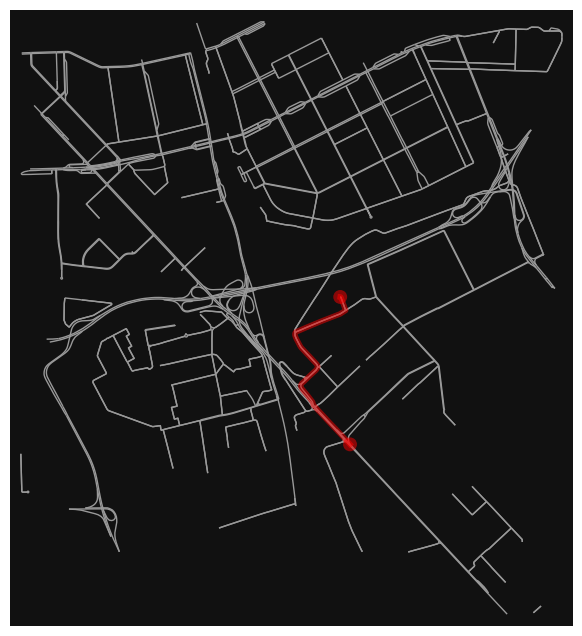

In [63]:
import networkx as nx
import osmnx as ox

source = 1605100326  # Евросиб
target = 1505621773  # Пятёрочка

for name, node in [
    ("Евросиб", source),
    ("Пятёрочка", target)
]:
    print(f"\n{name}:")
    print("Входящих рёбер:", G_road.in_degree(node))
    print("Исходящих рёбер:", G_road.out_degree(node))

# Обратный маршрут
reverse_route = nx.shortest_path(
    G_road,
    source=target,
    target=source,
    weight="length"
)

distance_km = nx.shortest_path_length(
    G_road,
    source=target,
    target=source,
    weight="length"
) / 1000

print(f"\nПятёрочка → Евросиб: {distance_km:.2f} км")

fig, ax = ox.plot.plot_graph_route(
    G_road,
    reverse_route,
    route_color="red",
    route_linewidth=4,
    node_size=0
)

**Результат.** Маршрут по первоначальной привязке **«Пятёрочка → Евросиб»** составил **2,84 км**. У обеих выбранных вершин есть входящие и исходящие рёбра, так что проблема не сводится к изолированной конечной точке.

### 7.9. Расстояние от границ логистических территорий до дорог

Вместо расстояния от одной точки проверяем расстояние **от полного полигона** до ближайших дорожных геометрий. Этот подход лучше подходит для территориально протяжённых объектов.

In [64]:
# Проецируем дорожный граф
G_proj = ox.project_graph(G_road)

# Получаем геометрию вершин и рёбер
road_nodes, road_edges = ox.graph_to_gdfs(G_proj)

# Проецируем логистические объекты
sites_metric = selected.to_crs(G_proj.graph["crs"])

for _, site in sites_metric.iterrows():
    geom = site.geometry

    # Расстояния до дорожных рёбер
    edge_distances = road_edges.geometry.distance(geom)

    nearest_edge = edge_distances.idxmin()
    nearest_distance = edge_distances.min()

    print(f"\n{site['name']}")
    print(f"До ближайшей дороги: {nearest_distance:.1f} м")
    print(f"Ближайшее дорожное ребро: {nearest_edge}")

    # Несколько ближайших вершин
    node_distances = road_nodes.geometry.distance(geom)

    print("Ближайшие вершины:")
    print(node_distances.nsmallest(5).round(1))


Терминал "Евросиб"
До ближайшей дороги: 18.3 м
Ближайшее дорожное ребро: (np.int64(10981950), np.int64(253818460), np.int64(0))
Ближайшие вершины:
osmid
482585154       97.9
13473119427    194.7
922394694      298.5
178243267      324.1
699886         334.2
dtype: float64

Распределительный центр «Пятерочка»
До ближайшей дороги: 22.8 м
Ближайшее дорожное ребро: (np.int64(1338883912), np.int64(3921667089), np.int64(0))
Ближайшие вершины:
osmid
1338883912    25.2
3921667089    40.6
1505621777    43.6
1505621773    52.0
1505621778    55.0
dtype: float64


**Наблюдение.** Ближайшие дорожные сегменты расположены всего в **18,3 м от «Евросиб»** и **22,8 м от «Пятёрочки»**. Это существенно меньше расстояний от внутренних точек до ранее выбранных вершин, но близость дороги ещё не подтверждает физический въезд.

### 7.10. Несколько предполагаемых точек подключения

Для каждой территории выбираем ближайшие дорожные рёбра в радиусе до **100 м** от полигона и собираем их конечные вершины. Это исследовательская эвристика, а не точное определение въездов.

In [65]:

import osmnx as ox
import networkx as nx
from shapely.geometry import Point

G_proj = ox.project_graph(G_road)
road_nodes, road_edges = ox.graph_to_gdfs(G_proj)

sites_metric = selected.to_crs(G_proj.graph["crs"])
sites_metric = sites_metric.set_index("id")

def find_access_candidates(site, n_edges=5, max_distance=100):
    # Расстояние от всей территории до дорожных рёбер
    distances = road_edges.geometry.distance(site.geometry)

    # Выбираем ближайшие рёбра в пределах 100 м
    nearby = (
        distances[distances <= max_distance]
        .nsmallest(n_edges)
    )

    candidates = set()

    for u, v, key in nearby.index:
        candidates.add(int(u))
        candidates.add(int(v))

    # Сортируем вершины по расстоянию до территории
    def node_distance(node):
        data = G_proj.nodes[node]
        point = Point(data["x"], data["y"])
        return site.geometry.distance(point)

    return sorted(candidates, key=node_distance)


eurosib_id = "osm:relation/5831201"
pyaterochka_id = "osm:relation/6950685"

eurosib_nodes = find_access_candidates(
    sites_metric.loc[eurosib_id]
)

pyaterochka_nodes = find_access_candidates(
    sites_metric.loc[pyaterochka_id]
)

print("Кандидаты для Евросиб:", eurosib_nodes)
print("Кандидаты для Пятёрочки:", pyaterochka_nodes)


Кандидаты для Евросиб: [482585154, 1502822034, 10593720, 10981950, 253818460, 1834089120, 342547413]
Кандидаты для Пятёрочки: [1338883912, 3921667089, 1505621777, 1505621780, 540190252]


### 7.11. Поиск кратчайших направленных маршрутов

Перебираем допустимые пары полученных дорожных вершин отдельно для каждого направления движения.

In [66]:

def find_best_route(G, start_nodes, end_nodes):
    best = None

    for u in start_nodes:
        for v in end_nodes:
            if u == v:
                continue

            try:
                distance = nx.shortest_path_length(
                    G, u, v, weight="length"
                )

                if best is None or distance < best["distance_m"]:
                    best = {
                        "source": u,
                        "target": v,
                        "distance_m": distance
                    }

            except nx.NetworkXNoPath:
                continue

    return best


forward = find_best_route(
    G_proj, eurosib_nodes, pyaterochka_nodes
)

backward = find_best_route(
    G_proj, pyaterochka_nodes, eurosib_nodes
)

for name, result in [
    ("Евросиб → Пятёрочка", forward),
    ("Пятёрочка → Евросиб", backward)
]:
    print(f"\n{name}")

    if result is None:
        print("Маршрут не найден")
    else:
        print("Начальная вершина:", result["source"])
        print("Конечная вершина:", result["target"])
        print(f"Длина: {result['distance_m'] / 1000:.2f} км")



Евросиб → Пятёрочка
Начальная вершина: 482585154
Конечная вершина: 1505621780
Длина: 2.59 км

Пятёрочка → Евросиб
Начальная вершина: 1505621777
Конечная вершина: 482585154
Длина: 1.84 км


**Результат улучшенного подхода.** Найдены оба маршрута: **2,59 км** по направлению **«Евросиб → Пятёрочка»** и **1,84 км** в обратном направлении. Следовательно, отсутствие пути в первом эксперименте было связано с **конкретным выбором дорожных вершин**, а не с полной недоступностью объектов по использованному графу.

### 7.12. Карта направленных маршрутов

Два варианта маршрута показываются отдельными цветами поверх OSM. Их геометрия соответствует выбранным дорожным участкам; начала и концы маршрутов расположены в **технических точках привязки**, а не обязательно у реальных въездов.

In [67]:

import folium
import networkx as nx
import osmnx as ox

m = folium.Map(
    location=[
        (south + north) / 2,
        (west + east) / 2
    ],
    zoom_start=13,
    tiles="OpenTopoMap"
)

# Показываем территории объектов
sites_layer = folium.FeatureGroup(
    name="Логистические объекты"
)

for _, site in selected.iterrows():
    folium.GeoJson(
        site.geometry.__geo_interface__,
        style_function=lambda f: {
            "color": "black",
            "weight": 3,
            "fillColor": "yellow",
            "fillOpacity": 0.25
        },
        tooltip=site["name"]
    ).add_to(sites_layer)

sites_layer.add_to(m)

# Конфигурация двух направлений
route_configs = [
    (
        "Евросиб → Пятёрочка",
        forward,
        "red"
    ),
    (
        "Пятёрочка → Евросиб",
        backward,
        "blue"
    )
]

# Координаты дорожных вершин
road_nodes_wgs = road_nodes.to_crs("EPSG:4326")

for label, result, color in route_configs:
    if result is None:
        continue

    u = result["source"]
    v = result["target"]

    route = nx.shortest_path(
        G_proj, u, v, weight="length"
    )

    # Геометрия реального маршрута
    route_gdf = ox.routing.route_to_gdf(
        G_proj, route
    ).to_crs("EPSG:4326")

    layer = folium.FeatureGroup(
        name=f"{label}: {result['distance_m']/1000:.2f} км"
    )

    folium.GeoJson(
        route_gdf.__geo_interface__,
        style_function=lambda f, c=color: {
            "color": c,
            "weight": 5,
            "opacity": 0.85
        },
        tooltip=label
    ).add_to(layer)

    # Начальная и конечная точки на дорогах
    for node_id, description in [
        (u, "Начало"),
        (v, "Конец")
    ]:
        point = road_nodes_wgs.loc[node_id].geometry

        folium.CircleMarker(
            location=[point.y, point.x],
            radius=6,
            color=color,
            fill=True,
            fill_opacity=1,
            tooltip=f"{description}: {label}"
        ).add_to(layer)

    layer.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m.fit_bounds([[south, west], [north, east]])

m


### 7.13. Контроль качества новых привязок

Проверяем геометрические разрывы между территориями и выбранными дорожными вершинами.

In [68]:
checks = [
    ("Евросиб → Пятёрочка", forward,
     eurosib_id, pyaterochka_id),

    ("Пятёрочка → Евросиб", backward,
     pyaterochka_id, eurosib_id)
]

for name, result, start_id, end_id in checks:
    if result is None:
        continue

    start_geom = sites_metric.loc[start_id].geometry
    end_geom = sites_metric.loc[end_id].geometry

    start_point = road_nodes.loc[
        result["source"]
    ].geometry

    end_point = road_nodes.loc[
        result["target"]
    ].geometry

    print(f"\n{name}")

    print(
        "От территории отправления до вершины:",
        round(start_geom.distance(start_point), 1),
        "м"
    )

    print(
        "От конечной вершины до территории:",
        round(end_geom.distance(end_point), 1),
        "м"
    )


Евросиб → Пятёрочка
От территории отправления до вершины: 97.9 м
От конечной вершины до территории: 69.0 м

Пятёрочка → Евросиб
От территории отправления до вершины: 43.6 м
От конечной вершины до территории: 97.9 м


**Результат.** Для направления «Евросиб → Пятёрочка» разрывы составили **97,9 м** и **69,0 м**, а для обратного — **43,6 м** и **97,9 м**. Эти расстояния не входят в рассчитанную длину проезда; нужно хранить качество подключения отдельно от длины маршрута.

### 7.14. Какие дороги входят в рассчитанные маршруты

Проверяем доступные атрибуты участков: `highway`, `oneway` и возможные ограничения грузового транспорта.

In [69]:

import pandas as pd
import networkx as nx
import osmnx as ox

def inspect_route(name, result):
    route = nx.shortest_path(
        G_proj,
        source=result["source"],
        target=result["target"],
        weight="length"
    )

    edges = ox.routing.route_to_gdf(
        G_proj, route
    )

    print(f"\n{name}")
    print(f"Количество участков: {len(edges)}")
    print(f"Длина маршрута: {edges['length'].sum()/1000:.2f} км")

    columns = [
        "highway",
        "service",
        "access",
        "motor_vehicle",
        "hgv",
        "maxweight",
        "oneway"
    ]

    for col in columns:
        if col in edges.columns:
            print(f"\n{col}:")
            print(
                edges[col]
                .fillna("Не указан")
                .astype(str)
                .value_counts()
            )

    return edges


forward_edges = inspect_route(
    "Евросиб → Пятёрочка", forward
)

backward_edges = inspect_route(
    "Пятёрочка → Евросиб", backward
)



Евросиб → Пятёрочка
Количество участков: 9
Длина маршрута: 2.59 км

highway:
highway
tertiary_link    6
tertiary         2
trunk            1
Name: count, dtype: int64

oneway:
oneway
False    5
True     4
Name: count, dtype: int64

Пятёрочка → Евросиб
Количество участков: 10
Длина маршрута: 1.84 км

highway:
highway
tertiary        6
trunk           3
unclassified    1
Name: count, dtype: int64

oneway:
oneway
False    6
True     4
Name: count, dtype: int64


**Результат.** Прямой маршрут состоит из **9 участков** (`tertiary_link`, `tertiary`, `trunk`), обратный — из **10** (`tertiary`, `trunk`, `unclassified`). В каждом направлении встречается **4 односторонних участка**. Сведений `hgv`, `access` и `motor_vehicle` в выбранных маршрутах не получено; поэтому **разрешённость движения грузовиков не подтверждена**.

## 8. Выбор логической модели транспортного графа

### 8.1. Альтернативный вариант: `MultiDiGraph`

Сначала проверяем направленный мультиграф: два маршрута между терминалами представлены **двумя рёбрами**, по одному на направление. Это удобно для направленной маршрутизации, но для укрупнённой логической модели приводит к отдельным записям на каждый вариант движения.

> Эта ячейка сохранена как **сравнение архитектурных вариантов**; далее для прототипа выбран другой тип графа.

In [70]:

import networkx as nx
import pandas as pd

# Создаём ориентированный мультиграф
G_logistics = nx.MultiDiGraph()

# Добавляем логистические объекты
for _, obj in selected.iterrows():
    G_logistics.add_node(
        obj["id"],
        name=obj["name"],
        object_type=obj["object_type"],
        latitude=float(obj["latitude"]),
        longitude=float(obj["longitude"])
    )

# Результаты ранее рассчитанных маршрутов
connections = [
    (eurosib_id, pyaterochka_id, forward),
    (pyaterochka_id, eurosib_id, backward)
]

# Добавляем направленные автомобильные связи
for source_id, target_id, result in connections:
    if result is None:
        continue

    # Восстанавливаем дорожный маршрут
    route = nx.shortest_path(
        G_proj,
        result["source"],
        result["target"],
        weight="length"
    )

    G_logistics.add_edge(
        source_id,
        target_id,
        key="road",
        transport_mode="road",
        distance_m=float(result["distance_m"]),
        road_start_node=int(result["source"]),
        road_end_node=int(result["target"]),
        route_nodes=route,
        connection_status="candidate",
        hgv_access="unknown"
    )

print("Логистических вершин:",
      G_logistics.number_of_nodes())

print("Транспортных связей:",
      G_logistics.number_of_edges())

# Выводим рёбра в таблицу
edge_records = []

for u, v, key, data in G_logistics.edges(
    keys=True, data=True
):
    edge_records.append({
        "source": G_logistics.nodes[u]["name"],
        "target": G_logistics.nodes[v]["name"],
        "mode": data["transport_mode"],
        "distance_km": round(
            data["distance_m"] / 1000, 2
        ),
        "status": data["connection_status"]
    })

display(pd.DataFrame(edge_records))

Логистических вершин: 2
Транспортных связей: 2


,source,target,mode,distance_km,status
0,"Терминал ""Евросиб""",Распределительный центр «Пятерочка»,road,2.59,candidate
1,Распределительный центр «Пятерочка»,"Терминал ""Евросиб""",road,1.84,candidate


### 8.2. Выбранный вариант: `MultiGraph`

Для укрупнённой транспортно-логистической модели используем `NetworkX.MultiGraph`: **одна логическая связь на вид транспорта между парой объектов**. Если расстояния в прямом и обратном направлениях отличаются, оба значения сохраняются в атрибутах ребра (`distance_forward_m`, `distance_backward_m`).

**Ограничение:** стандартные алгоритмы NetworkX будут считать это ребро неориентированным. Для задач с учётом направления позже потребуется специальная функция обработки или производный направленный граф.

In [71]:

import networkx as nx

G_logistics = nx.MultiGraph()

# Добавляем логистические объекты
for _, obj in selected.iterrows():
    G_logistics.add_node(
        obj["id"],
        name=obj["name"],
        object_type=obj["object_type"],
        region="Санкт-Петербург"
    )

# Формируем одну автомобильную связь
# с сохранением расстояний в обоих направлениях
G_logistics.add_edge(
    eurosib_id,
    pyaterochka_id,
    key="road",
    transport_mode="road",
    distance_forward_m=(
        forward["distance_m"] if forward else None
    ),
    distance_backward_m=(
        backward["distance_m"] if backward else None
    ),
    node_a=eurosib_id,
    node_b=pyaterochka_id,
    connection_status="candidate"
)

print("Вершин:", G_logistics.number_of_nodes())
print("Рёбер:", G_logistics.number_of_edges())

for u, v, key, data in G_logistics.edges(
    keys=True, data=True
):
    print("\nСвязь:", key)
    print("Объекты:", G_logistics.nodes[u]["name"],
          "—", G_logistics.nodes[v]["name"])
    print("Расстояние A → B:", data["distance_forward_m"])
    print("Расстояние B → A:", data["distance_backward_m"])


Вершин: 2
Рёбер: 1

Связь: road
Объекты: Терминал "Евросиб" — Распределительный центр «Пятерочка»
Расстояние A → B: 2593.525090443022
Расстояние B → A: 1844.2110205383453


**Итог сравнения.** Для двух объектов получен **1 автомобильный логический край** вместо 2 направленных. При этом разная длина обоих направлений **сохранена**. Модель допускает добавление параллельных рёбер для других видов транспорта, не смешивая автомобильные и железнодорожные характеристики.

### 8.3. Принцип работы с несколькими регионами

Создаём **условный пример** из двух логистических хабов в разных регионах и добавляем между ними два вида транспорта. Здесь проверяется **структура данных**, а не фактическая связность Санкт-Петербурга и Ленинградской области.

In [72]:

G_demo = nx.MultiGraph()

G_demo.add_node(
    "hub_spb",
    region="Санкт-Петербург",
    object_type="logistics_hub"
)

G_demo.add_node(
    "hub_len",
    region="Ленинградская область",
    object_type="logistics_hub"
)

# Две условные транспортные связи
G_demo.add_edge(
    "hub_spb", "hub_len",
    key="road",
    transport_mode="road"
)

G_demo.add_edge(
    "hub_spb", "hub_len",
    key="rail",
    transport_mode="rail"
)

print("Вершин:", G_demo.number_of_nodes())
print("Рёбер:", G_demo.number_of_edges())

for u, v, key in G_demo.edges(keys=True):
    print(u, "—", v, "|", key)


Вершин: 2
Рёбер: 2
hub_spb — hub_len | road
hub_spb — hub_len | rail


**Вывод.** `MultiGraph` технически поддерживает **несколько рёбер разного типа между объектами разных регионов**. Регион — атрибут вершины, поэтому сама модель не ограничена границами одной административной территории. Подбор действительных межрегиональных маршрутов остаётся дальнейшей задачей.

## 9. Демонстрационный граф нескольких логистических объектов

### 9.1. Отбор объектов

Для проверки масштабирования от двух вершин переходим к подмножеству складской инфраструктуры **в районе Шушар**. Берём склады и логистические территории из предварительного списка графовых вершин. Порты не добавляем: они находятся в другой области, а морские и железнодорожные маршруты пока не реализованы.

In [73]:

import osmnx as ox
import networkx as nx
import geopandas as gpd
import pandas as pd
import numpy as np

# Берём склады и логистические территории
logistics = graph_nodes[
    graph_nodes["object_type"].isin([
        "warehouse",
        "logistics_site"
    ])
].copy()

# Загруженный ранее дорожный граф
G_proj = ox.project_graph(G_road)
road_nodes, road_edges = ox.graph_to_gdfs(G_proj)

# Приводим геометрии к одной системе координат
logistics = logistics.to_crs(G_proj.graph["crs"])
logistics = logistics.set_index("id", drop=False)

print("Всего логистических объектов:", len(logistics))

display(
    logistics["object_type"]
    .value_counts()
    .rename_axis("Тип")
    .reset_index(name="Количество")
)


Всего логистических объектов: 27


,Тип,Количество
0,warehouse,22
1,logistics_site,5


**Исходная выборка для демонстрации:** **27 логистических объектов** — **22 склада и 5 логистических территорий**. Состав основан на тестовом реестре; потенциальные дубли между некоторыми безымянными складами и комплексами ещё требуют проверки.

### 9.2. Отбор потенциальных пар методом k ближайших соседей

Для каждого объекта выбираем **3 ближайших соседа** по географическому расстоянию между репрезентативными точками. Этот критерий формирует **разреженный демонстрационный граф** и не претендует на реконструкцию реальных цепочек поставок или межрегиональных грузопотоков.

In [74]:

K = 3

# Точки для определения географической близости
site_points = logistics.geometry.representative_point()

pairs = set()

for obj_id in logistics.index:
    point = site_points.loc[obj_id]

    distances = site_points.distance(point)
    distances = distances.drop(obj_id)

    nearest = distances.nsmallest(K)

    for neighbor_id in nearest.index:
        # Исключаем дублирование пары A-B и B-A
        pair = tuple(sorted([obj_id, neighbor_id]))
        pairs.add(pair)

print("Количество потенциальных пар:", len(pairs))


Количество потенциальных пар: 59


**Результат.** После исключения дубликатов пар A–B и B–A получено **59 потенциальных пар** для проверки по дорожной сети. Отбор k ближайших соседей не гарантирует связность графа и может пропустить дальние, но экономически важные связи.

### 9.3. Предполагаемые точки подключения к дорожной сети

Для каждого объекта ищем конечные вершины **до пяти ближайших дорожных рёбер в пределах 150 м** от геометрии. Результаты интерпретируются как **кандидаты на подключение**, не как подтверждённые въезды.

In [75]:

from shapely.geometry import Point

def find_access_nodes(geom, max_distance=150, n_edges=5):
    distances = road_edges.geometry.distance(geom)

    nearby = (
        distances[distances <= max_distance]
        .nsmallest(n_edges)
    )

    nodes = set()

    for u, v, key in nearby.index:
        nodes.add(int(u))
        nodes.add(int(v))

    return list(nodes)


# Для каждого объекта определяем кандидатов на подключение
access_nodes = {}

for obj_id, row in logistics.iterrows():
    access_nodes[obj_id] = find_access_nodes(
        row.geometry
    )

print(
    "Объектов с найденными точками подключения:",
    sum(bool(nodes) for nodes in access_nodes.values())
)

print(
    "Без точек подключения:",
    sum(not nodes for nodes in access_nodes.values())
)


Объектов с найденными точками подключения: 27
Без точек подключения: 0


**Результат.** Для всех **27** объектов удалось подобрать хотя бы одну потенциальную дорожную вершину. Это говорит о покрытии выбранным графом на уровне пространственной близости, но не является проверкой доступа грузового транспорта.

### 9.4. Расчёт направленной дорожной достижимости

Используем `multi_source_dijkstra_path_length()` от наборов точек доступа и атрибут `length` для определения расстояний между кандидатами. Этот подход позволяет переиспользовать результаты при проверке многих пар объектов.

> Если два объекта используют одну дорожную вершину, нулевой маршрут здесь намеренно исключается. Длина возможных внутренних проездов по территориям в расчёт не входит.

In [76]:

# Длины маршрутов от возможных точек доступа каждого объекта
distances_from = {}

for obj_id, nodes in access_nodes.items():
    if not nodes:
        distances_from[obj_id] = {}
        continue

    distances_from[obj_id] = (
        nx.multi_source_dijkstra_path_length(
            G_proj,
            sources=set(nodes),
            weight="length"
        )
    )


def get_distance(source_id, target_id):
    distances = distances_from[source_id]
    targets = access_nodes[target_id]

    # Исключаем нулевую длину, возникающую,
    # если объекты используют одну дорожную вершину
    available = [
        distances[node]
        for node in targets
        if node in distances and distances[node] > 0
    ]

    return min(available) if available else None


### 9.5. Создание расширенного `MultiGraph`

Добавляем **все 27 объектов как вершины**. Автомобильная связь между парой появляется, если по выбранным кандидатам найден хотя бы один направленный путь. На ребре храним отдельные расстояния A→B и B→A и статус `candidate`.

In [77]:

G_logistics_big = nx.MultiGraph()

# Добавляем все логистические объекты
for obj_id, row in logistics.iterrows():
    name = row["name"]

    if pd.isna(name):
        name = f"Склад {obj_id.split('/')[-1]}"

    G_logistics_big.add_node(
        obj_id,
        name=name,
        object_type=row["object_type"],
        latitude=float(row["latitude"]),
        longitude=float(row["longitude"])
    )

# Добавляем автомобильные связи
for a, b in sorted(pairs):

    distance_ab = get_distance(a, b)
    distance_ba = get_distance(b, a)

    # Если не нашли маршрут ни в одну сторону
    if distance_ab is None and distance_ba is None:
        continue

    G_logistics_big.add_edge(
        a,
        b,
        key="road",
        transport_mode="road",
        node_a=a,
        node_b=b,
        distance_ab_m=distance_ab,
        distance_ba_m=distance_ba,
        connection_status="candidate"
    )

print("Вершин:", G_logistics_big.number_of_nodes())
print("Рёбер:", G_logistics_big.number_of_edges())

print(
    "Изолированных вершин:",
    len(list(nx.isolates(G_logistics_big)))
)

print(
    "Компонент связности:",
    nx.number_connected_components(G_logistics_big)
)


Вершин: 27
Рёбер: 43
Изолированных вершин: 1
Компонент связности: 3


**Результат построения:** **27 вершин, 43 логические автомобильные связи, 1 изолированная вершина и 3 компоненты связности**. Это **не ошибка NetworkX**: демонстрационный выбор k ближайших соседей и неполная дорожная достижимость могут создавать несвязные части графа.

**Интерпретация:** получен работоспособный прототип разреженного графа потенциальной автомобильной доступности; его связность и географические ограничения зависят от выбора пар и точек подключения.

### 9.6. Первая визуализация: логический граф

Для наглядности соединяем репрезентативные точки объектов **прямыми линиями**. Важное различие: прямая линия — это **только обозначение логического ребра**, а его длина хранится по рассчитанному дорожному маршруту. Она **не является геометрией дороги**.

In [78]:

import folium

m = folium.Map(
    location=[59.81, 30.39],
    zoom_start=12,
    tiles="OpenTopoMap"
)

# Рёбра логистического графа
edges_layer = folium.FeatureGroup(
    name="Автомобильные связи"
)

for a, b, data in G_logistics_big.edges(data=True):

    node_a = G_logistics_big.nodes[a]
    node_b = G_logistics_big.nodes[b]

    ab = data["distance_ab_m"]
    ba = data["distance_ba_m"]

    def fmt(value):
        return f"{value / 1000:.2f} км" if value is not None else "нет маршрута"

    tooltip = (
        f"{node_a['name']} — {node_b['name']}"
        f" | A→B: {fmt(ab)}"
        f" | B→A: {fmt(ba)}"
    )

    folium.PolyLine(
        locations=[
            [node_a["latitude"], node_a["longitude"]],
            [node_b["latitude"], node_b["longitude"]]
        ],
        color="blue",
        weight=2,
        opacity=0.45,
        tooltip=tooltip
    ).add_to(edges_layer)

edges_layer.add_to(m)

# Вершины
nodes_layer = folium.FeatureGroup(
    name="Логистические объекты"
)

for node_id, data in G_logistics_big.nodes(data=True):

    is_site = data["object_type"] == "logistics_site"

    folium.CircleMarker(
        location=[data["latitude"], data["longitude"]],
        radius=8 if is_site else 5,
        color="red" if is_site else "orange",
        fill=True,
        fill_opacity=0.9,
        tooltip=data["name"],
        popup=(
            f"{data['name']}<br>"
            f"Тип: {data['object_type']}<br>"
            f"Связей: {G_logistics_big.degree(node_id)}"
        )
    ).add_to(nodes_layer)

nodes_layer.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)

m


**Наблюдение по карте.** Появляется общая структура из нескольких логистических групп, однако прямые линии местами пересекают здания и территории. Такой вид полезен для объяснения **топологии логистического графа**, но непригоден для демонстрации реальных автомобильных трасс.

### 9.7. Восстановление дорожной геометрии для логических связей

Для уже сформированных 43 рёбер рассчитываем маршруты как последовательности вершин дорожного графа. **Повторного обращения к Overpass не требуется**: используются данные `G_proj`.

In [79]:

import networkx as nx
import osmnx as ox

# Рассчитываем маршруты от возможных точек доступа
# каждого логистического объекта
route_cache = {}

for obj_id, nodes in access_nodes.items():
    valid_nodes = {
        int(n) for n in nodes if n in G_proj
    }

    if not valid_nodes:
        route_cache[obj_id] = None
        continue

    lengths, paths = nx.multi_source_dijkstra(
        G_proj,
        sources=valid_nodes,
        weight="length"
    )

    route_cache[obj_id] = {
        "lengths": lengths,
        "paths": paths
    }


def get_road_route(source_id, target_id):
    """Маршрут между кандидатами на дорожный доступ."""

    data = route_cache.get(source_id)

    if data is None:
        return None

    lengths = data["lengths"]
    paths = data["paths"]

    variants = []

    for target_node in access_nodes[target_id]:
        if target_node not in lengths:
            continue

        distance = lengths[target_node]

        # Сохраняем правило предыдущего эксперимента
        if distance <= 0:
            continue

        variants.append((distance, target_node))

    if not variants:
        return None

    distance, target_node = min(variants)

    return {
        "distance_m": float(distance),
        "route_nodes": paths[target_node]
    }


# Восстанавливаем маршруты для всех рёбер
route_results = {}

for u, v, key, data in G_logistics_big.edges(
    keys=True, data=True
):
    a = data.get("node_a", u)
    b = data.get("node_b", v)

    route_ab = get_road_route(a, b)
    route_ba = get_road_route(b, a)

    route_results[(a, b, key)] = {
        "ab": route_ab,
        "ba": route_ba
    }

    # Сохраняем маршруты в атрибутах ребра
    data["route_ab"] = (
        route_ab["route_nodes"] if route_ab else None
    )
    data["route_ba"] = (
        route_ba["route_nodes"] if route_ba else None
    )

print("Обработано связей:", len(route_results))
print(
    "Направленных маршрутов:",
    sum(
        result is not None
        for routes in route_results.values()
        for result in routes.values()
    )
)


Обработано связей: 43
Направленных маршрутов: 76


**Результат.** Обработано **43 логические связи**, восстановлено **76 направленных маршрутов** из теоретически возможных 86. Следовательно, для некоторых пар маршрут представлен только в одном направлении. Логический `MultiGraph` при этом остаётся графом из 43 рёбер.

### 9.8. Вторая визуализация: маршруты по дорожной сети

Заменяем прямолинейные обозначения рёбер геометрией реально загруженных дорожных участков. Более короткое из найденных направлений показано как основной слой, обратное — как дополнительный слой карты.

In [80]:

import folium
import pandas as pd

m = folium.Map(
    location=[59.81, 30.39],
    zoom_start=12,
    tiles="OpenTopoMap"
)

# Два слоя маршрутов
main_layer = folium.FeatureGroup(
    name="Основные маршруты по дорогам",
    show=True
)

reverse_layer = folium.FeatureGroup(
    name="Альтернативные направления",
    show=False
)


def draw_route(layer, route, source_id, target_id, color):
    """Добавляет маршрут по реальным дорожным участкам."""

    if route is None:
        return

    # Получаем геометрию маршрута
    route_gdf = ox.routing.route_to_gdf(
        G_proj,
        route["route_nodes"],
        weight="length"
    ).to_crs("EPSG:4326")

    source_name = G_logistics_big.nodes[source_id]["name"]
    target_name = G_logistics_big.nodes[target_id]["name"]

    tooltip = (
        f"{source_name} → {target_name}: "
        f"{route['distance_m'] / 1000:.2f} км"
    )

    folium.GeoJson(
        route_gdf[["geometry"]].to_json(),
        style_function=lambda feature, c=color: {
            "color": c,
            "weight": 3,
            "opacity": 0.75
        },
        tooltip=tooltip
    ).add_to(layer)


# Рисуем все маршруты
for (a, b, key), routes in route_results.items():

    available = []

    if routes["ab"] is not None:
        available.append((a, b, routes["ab"]))

    if routes["ba"] is not None:
        available.append((b, a, routes["ba"]))

    if not available:
        continue

    # Более короткое направление
    available.sort(
        key=lambda x: x[2]["distance_m"]
    )

    src, dst, route = available[0]

    draw_route(
        main_layer, route, src, dst, "blue"
    )

    # Второе направление, если существует
    if len(available) > 1:
        src, dst, route = available[1]

        draw_route(
            reverse_layer, route, src, dst, "red"
        )


main_layer.add_to(m)
reverse_layer.add_to(m)


# Вершины логистического графа
nodes_layer = folium.FeatureGroup(
    name="Логистические объекты"
)

for node_id, data in G_logistics_big.nodes(data=True):

    is_site = data["object_type"] == "logistics_site"

    folium.CircleMarker(
        location=[
            data["latitude"],
            data["longitude"]
        ],
        radius=7 if is_site else 5,
        color="red" if is_site else "orange",
        fill=True,
        fill_opacity=0.9,
        tooltip=data["name"],
        popup=(
            f"<b>{data['name']}</b><br>"
            f"Тип: {data['object_type']}<br>"
            f"Связей: {G_logistics_big.degree(node_id)}"
        )
    ).add_to(nodes_layer)

nodes_layer.add_to(m)

folium.LayerControl(
    collapsed=False
).add_to(m)

m


**Наблюдение по карте.** Линии маршрутов теперь следуют улицам и развязкам, однако не всегда визуально доходят до маркеров складов и терминалов. Причина: дорожный маршрут начинается и заканчивается в **выбранных дорожных вершинах**, тогда как маркер логистического объекта расположен внутри его геометрии.

### 9.9. Итоговая визуализация: объекты, маршруты и точки подключения

Дополняем карту **техническими дорожными вершинами**, которые использовались при расчётах. Пунктир соединяет внутреннюю точку логистического объекта с выбранной дорожной вершиной; сплошные линии показывают маршруты по дорогам. Так становится видно, **какая логистическая вершина через какие точки сопоставлена с транспортной сетью**.

> Пунктирные соединения не являются подтверждёнными физическими подъездами и не включены в расчёт дорожных расстояний. Итоговая карта служит пояснением двух уровней модели — логистических объектов и дорожной инфраструктуры.

In [81]:
import folium
import geopandas as gpd
from shapely.geometry import Point
from collections import defaultdict
import osmnx as ox

# Геометрия дорожных вершин
road_nodes_gdf, road_edges_gdf = ox.graph_to_gdfs(G_proj)
road_nodes_wgs = road_nodes_gdf.to_crs("EPSG:4326")

# Логистические объекты в WGS84
logistics_wgs = logistics.to_crs("EPSG:4326").copy()

# Точки объектов (репрезентативные)
object_points = logistics_wgs.copy()
object_points["geometry"] = object_points.geometry.representative_point()

# Собираем информацию:
# какие дорожные вершины реально использовались в маршрутах
used_access = defaultdict(list)

for (a, b, key), routes in route_results.items():

    # направление A -> B
    if routes["ab"] is not None:
        route_nodes = routes["ab"]["route_nodes"]
        start_node = route_nodes[0]
        end_node = route_nodes[-1]

        used_access[(a, start_node)].append(f"к {G_logistics_big.nodes[b]['name']}")
        used_access[(b, end_node)].append(f"из {G_logistics_big.nodes[a]['name']}")

    # направление B -> A
    if routes["ba"] is not None:
        route_nodes = routes["ba"]["route_nodes"]
        start_node = route_nodes[0]
        end_node = route_nodes[-1]

        used_access[(b, start_node)].append(f"к {G_logistics_big.nodes[a]['name']}")
        used_access[(a, end_node)].append(f"из {G_logistics_big.nodes[b]['name']}")

# Карта
m = folium.Map(
    location=[59.81, 30.39],
    zoom_start=12,
    tiles="OpenTopoMap"
)

# 1. Реальные маршруты по дорогам
routes_layer = folium.FeatureGroup(
    name="Маршруты по дорогам",
    show=True
)

for (a, b, key), routes in route_results.items():
    for direction, color, src, dst in [
        ("ab", "blue", a, b),
        ("ba", "red", b, a)
    ]:
        route = routes[direction]
        if route is None:
            continue

        route_gdf = ox.routing.route_to_gdf(
            G_proj,
            route["route_nodes"],
            weight="length"
        ).to_crs("EPSG:4326")

        tooltip = (
            f"{G_logistics_big.nodes[src]['name']} → "
            f"{G_logistics_big.nodes[dst]['name']} | "
            f"{route['distance_m'] / 1000:.2f} км"
        )

        folium.GeoJson(
            route_gdf[["geometry"]].to_json(),
            style_function=lambda feature, c=color: {
                "color": c,
                "weight": 3,
                "opacity": 0.75
            },
            tooltip=tooltip
        ).add_to(routes_layer)

routes_layer.add_to(m)

# 2. Логистические объекты
objects_layer = folium.FeatureGroup(
    name="Логистические объекты",
    show=True
)

for node_id, data in G_logistics_big.nodes(data=True):
    is_site = data["object_type"] == "logistics_site"

    folium.CircleMarker(
        location=[data["latitude"], data["longitude"]],
        radius=8 if is_site else 5,
        color="red" if is_site else "orange",
        fill=True,
        fill_opacity=0.9,
        tooltip=data["name"],
        popup=(
            f"<b>{data['name']}</b><br>"
            f"Тип: {data['object_type']}<br>"
            f"Связей: {G_logistics_big.degree(node_id)}"
        )
    ).add_to(objects_layer)

objects_layer.add_to(m)

# 3. Точки подключения к дорожной сети
access_points_layer = folium.FeatureGroup(
    name="Точки подключения",
    show=True
)

for (obj_id, road_node), labels in used_access.items():
    point = road_nodes_wgs.loc[road_node].geometry

    popup_text = (
        f"<b>Дорожная вершина {road_node}</b><br>"
        f"Объект: {G_logistics_big.nodes[obj_id]['name']}<br>"
        f"Использование:<br>- " + "<br>- ".join(sorted(set(labels)))
    )

    folium.CircleMarker(
        location=[point.y, point.x],
        radius=4,
        color="black",
        fill=True,
        fill_color="cyan",
        fill_opacity=1,
        tooltip=f"Точка подключения: {G_logistics_big.nodes[obj_id]['name']}",
        popup=popup_text
    ).add_to(access_points_layer)

access_points_layer.add_to(m)

# 4. Пунктирные связи объект -> точка подключения
connectors_layer = folium.FeatureGroup(
    name="Связи объект → точка подключения",
    show=True
)

for (obj_id, road_node), labels in used_access.items():
    obj_geom = object_points.loc[obj_id].geometry
    road_geom = road_nodes_wgs.loc[road_node].geometry

    folium.PolyLine(
        locations=[
            [obj_geom.y, obj_geom.x],
            [road_geom.y, road_geom.x]
        ],
        color="gray",
        weight=2,
        opacity=0.7,
        dash_array="6, 6",
        tooltip=(
            f"{G_logistics_big.nodes[obj_id]['name']} → "
            f"дорожная вершина {road_node}"
        )
    ).add_to(connectors_layer)

connectors_layer.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m

## 10. Итоги исследования и проектные решения

### Полученные результаты

| Исследовательский этап | Результат на тестовых данных |
|---|---|
| Дорожная сеть Шушар, расширенная область | 559 вершин и 1023 ребра |
| Складские здания | 24 объекта |
| Промышленные территории | 106 объектов; 21 из 24 складов попал в территории |
| Логистические территории-кандидаты | 14, из них 5 именованных территорий включены в реестр |
| Железнодорожные станции | 6, в том числе 1 станция метро |
| Железнодорожные линии | 103 OSM-участка; 68 `spur` или `siding` |
| Портовые объекты | 12, из них 10 с `port=cargo` |
| Единый исходный реестр | 44 записи с уникальными OSM ID |
| Предварительные кандидаты в вершины | 42 после временного исключения двух вложенных складов |
| Демонстрационный логистический `MultiGraph` | **27 вершин, 43 ребра, 3 компоненты, 1 изолированная вершина** |
| Восстановленные дорожные маршруты | 76 направленных маршрутов для 43 логических рёбер |

### Предлагаемая модель

**Уровень 1 — исходная инфраструктура.** OSM-объекты, геометрии, дорожные и железнодорожные линии, портовые территории. Дорожная сеть представляется направленным графом и используется для расчётов маршрутов.

**Уровень 2 — логистический граф.** Вершины соответствуют потенциальным логистическим объектам (складам, комплексам, терминалам, станциям, портам). Между парой вершин может существовать **одно логическое ребро для каждого вида транспорта**: авто, железная дорога, море. Поэтому для укрупнённой модели выбран `NetworkX.MultiGraph`, а характеристики обоих направлений хранятся в атрибутах связи.

**Масштабирование на несколько регионов.** Административная принадлежность хранится как атрибут объекта; модель графа сама по себе не ограничена одной областью. **Реальные межрегиональные маршруты в этом ноутбуке не строились**.

### Ограничения и дальнейшая работа

1. **Неполнота OSM.** Наличие и детализация тегов существенно различаются для складов, станций и портов; имя и полигон не всегда подтверждают роль объекта.
2. **Неустановленные точки доступа.** Предполагаемые привязки к дорожным вершинам могут не соответствовать реальным въездам или разрешённым грузовым маршрутам.
3. **Структурные допущения.** `k=3` и радиусы поиска дорожных рёбер выбраны **только для демонстрации**; они не подтверждают реальные связи между предприятиями.
4. **Мультимодальность.** Подготовлены исходные сведения по Ж/Д и морским объектам, но железнодорожные и морские маршруты ещё не включены в итоговый граф.
5. **Направленность.** `MultiGraph` хранит два значения длины, но стандартные алгоритмы NetworkX не учитывают эти ограничения автоматически. Для направленных запросов потребуется отдельная реализация.
6. **Внешняя инфраструктура.** Доступность Overpass и картографических подложек нестабильна; необходимы сохранение данных и обработка ошибок.

**Общий вывод.** Эксперименты показывают реализуемость двухуровневой модели: сначала формируется каталог потенциальных логистических объектов, затем поверх транспортной инфраструктуры рассчитываются возможные связи между ними. Разделение этих уровней позволяет сохранять происхождение данных, отдельно улучшать определение объектов и маршрутизацию и в дальнейшем распространять граф на несколько регионов.

### Что остаётся за рамками текущего этапа

- Проверка и уточнение точек въезда, железнодорожных подключений и морских маршрутов.
- Проектирование промышленной реализации графового модуля и интерфейса API.
- **Выбор и обоснование графовых метрик — отдельный следующий этап исследования.**

### Основные материалы

- [OSMnx: официальная документация](https://osmnx.readthedocs.io/)
- [NetworkX: типы графов](https://networkx.org/documentation/stable/reference/classes/)
- [GeoPandas: пространственное соединение](https://geopandas.org/en/stable/docs/reference/api/geopandas.sjoin.html)
- [OpenStreetMap Wiki: теги](https://wiki.openstreetmap.org/wiki/Map_features)
- [Проект предыдущего года](https://github.com/citec-spbu/analyze-logistic)